# E92 · Where should the next Argo floats go? An exact Gaussian process that did not earn its price

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify. Part of the large-model series |
| **Data** | Real: 40,343 Argo profiles of temperature at 100 dbar in the open North Atlantic, 20-55N, 2023-2025 (Argo GDAC, SEANOE, doi:10.17882/42182, CC BY 4.0), as anomalies from a local 2015-2022 climatology; Natural Earth coastlines (public domain). A reader's run loads the table, small JSON files of a stored run and a 1.3 MB summary |
| **Time** | About 1.5 minutes on 2 cores, under 2 GB. The notebook replays a stored run; the heavy run is not repeated |
| **You will learn** | An **exact Gaussian process** on 23,939 points with a two-scale space-time **Matern** kernel, a blocked gradient, **Laplace** with **PSIS**-weighted Sobol points and a **NUTS audit** in PyMC · why **float32** can be silently wrong · the exact fit against **local windows**, **Vecchia** and an exact **nonstationary amplitude**, by **CRPS** and a **paired whole-float bootstrap** · **calibration by region** · **greedy design** of drifting floats with **common random drift**, a **gap-filling** baseline and stability checks · a **natural experiment** that tests the objective · a hand-made **Lambert conformal** map |

> **Do not rerun the heavy parts on limited hardware.** Every fitted number here comes from one stored
> run of 7.2 hours (measured, 2026-11-03 to 2026-11-04) on an NVIDIA RTX 3090 Ti with an AMD Ryzen 9 5950X
> and 64 GB of memory: 2.9 hours of GPU stages peaking at 14.1 GiB of GPU memory, and four PyMC chains of
> 6 hours each on four CPU cores beside them; part 9 adds a 26-minute GPU rerun of the design. A normal
> run loads `results/E92/` (small JSON files) and `data/e92_replay.npz`, redraws every figure and recomputes the scores, a small float32 experiment and a
> PyMC log density on a CPU; it needs no GPU and refuses any other run level. The heavy run is
> `tools/run_e92_full.py`, with `tools/run_e92_audit.py` for the PyMC chains and `tools/score_e92.py` for
> the scores (`tools/score_e92_masked.py` for the rerun).

## The setting

About 4,000 Argo floats drift through the world's oceans. Every ten days each one sinks to 2,000 m, rises
measuring temperature and salinity, sends its profile by satellite and sinks again. They are the backbone of
what we know about the upper ocean's heat, and a float lasts only a few years, so every national programme
has the same question every year: where should the new ones go?

Suppose the coordinator of such a programme can place **20 floats in the North Atlantic next year**. They
want the launches that will most reduce the uncertainty of the map of upper-ocean temperature, how much of
that advice depends on our model, and a comparison with what they would do anyway, which is to fill the
biggest holes in the network. A float drifts, so a launch site is not a station but the start of a track.

Turning scattered profiles into a map is a spatial statistics problem with a long history. Roemmich &
Gilson (2009) mapped Argo temperature by optimal interpolation, which is kriging with a fixed covariance.
Kuusela & Stein (2018) treated the anomalies from a mean field as a Gaussian process, fitted its
covariance in moving windows, and showed that **nonstationarity** and **heavy tails** were what made the
uncertainty right; they mapped 10, 300 and 1,500 dbar. We use **100 dbar**: deep enough to be below most
of the day-to-day weather of the surface mixed layer, shallow enough to keep the seasonal cycle and the
eddies, and reached by every profiling float, including those that do not report near the surface.

The tool on offer is the most expensive one in the series. With 23,939 profiles in two years, an **exact
Gaussian process** needs a 23,939 x 23,939 covariance matrix and its Cholesky factor, about $5 \times
10^{12}$ floating-point operations per evaluation of the log density and three times that for its
gradient. A consumer GPU does that in a second in float32, and the stored run did it hundreds of times.
The cheaper alternatives are old and good: **local windows**, each with its own small GP, and the
**Vecchia approximation** (Vecchia 1988; Katzfuss & Guinness 2021), which writes the joint density as a
product of conditionals on a few nearest earlier points. The question this notebook asks is the one any
planner should ask before paying for exactness: **did the exact fit change the map, or the advice?**

The objective for siting is the **mean posterior variance** of the 100 dbar anomaly over the open North
Atlantic in 2025. E89 sited air monitors by the *value* of a reading for a regulatory call, and found that
uncertainty and value are different maps (E89, section 5, *Uncertainty is not value*). The two notebooks
do not contradict each other: they assume different losses. If the product is the map and every error
costs its square, the best report is the posterior mean, its expected loss is the posterior variance, and
the value of a float is the variance it removes. That is an assumption about the coordinator, and we say
so where the advice is given. "Removes the most map uncertainty" is the claim; "most valuable" is not.

Everything that needs the GPU ran once and is replayed here. We chose the scores, the comparisons and the
way the design would become advice before that run, and three things went wrong in it; each is told where
it happens. Two choices came earlier, on trial runs, after first attempts failed: the climatology and how to
read the real-time profiles (part 1). One came after: the first design let floats launch on continental
shelves, so we reran it on water a float can work in, and part 9 shows both runs side by side.

## The plan

| Part | Question | Tool |
|---|---|---|
| 1 | What do the floats see? | the 100 dbar table, anomalies, heavy tails at the fronts, a hexbin map |
| 2 | How far does a float drift? | real tracks moved to a common origin |
| 3 | What is the model, and what does it cost? | a two-scale space-time Matern kernel, the PyMC version, a price chart |
| 4 | Where does the fit land? | the mode at n = 23,939, a nugget at its prior edge, Laplace, PSIS, a NUTS check |
| 5 | What does the map say? | posterior mean and sd on a Lambert projection |
| 6 | Was exactness worth it? | a race of exact, windows, Vecchia and an amplitude map, by CRPS (failure 1's setting) |
| 7 | Is the uncertainty right? | coverage by region and on a map (failure 1), the amplitude fix |
| 8 | Can float32 be trusted? | log determinant error against condition number (failure 2) |
| 9 | Where should the 20 floats go? | greedy design with drift, gap-filling, stability (failure 3) |
| 10 | Does the objective predict anything? | the 2025 launches as a natural experiment |
| 11 | What do we tell the programme? | the recommendation and what would change it |

In [1]:
import os

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "2")  # before NumPy
os.environ["JAX_PLATFORMS"] = "cpu"  # every GPU number here is stored: a reader's run never starts one

import hashlib
import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import HTML, Markdown, display
from matplotlib.animation import FuncAnimation
from matplotlib.collections import PolyCollection
from matplotlib.colors import LogNorm, TwoSlopeNorm
from matplotlib.lines import Line2D
from scipy import stats

from pymc_challenges import data
from pymc_challenges.bigrun import PreflightError, Store, banner

# ArviZ leaves a lazy stub under "jax", and Matplotlib's first plot tests `sys.modules.get("jax")`, which
# would import all of JAX for nothing. Nothing here uses JAX, so the stub goes.
sys.modules.pop("jax", None)

RANDOM_SEED = 92
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning, module="pytensor")

LEVEL = os.environ.get("PYMC_CHALLENGES_RUN", "").strip().lower() or "replay"
if LEVEL != "replay":
    raise PreflightError(f"PYMC_CHALLENGES_RUN={LEVEL!r}: E92 has one level, replay. The heavy run is not a "
                         "notebook cell: it is tools/run_e92_full.py, and it needs a 24 GB GPU and most of a night.")
started = time.perf_counter()
CORES = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else os.cpu_count()

store = Store("E92")
scores = store.load_json("scores")  # every number the stored run produced, with its checks
p3 = store.load_json("pilot_p3")  # the price ladder at n = 2,000-20,000
nat_exp = store.load_json("natural_experiment")
amp = store.load_json("amp_map")
data.describe("e92_replay")
pack = np.load(data.path("e92_replay"), allow_pickle=False)
print(f"\nNotice carried in the file: {pack['notice']}\n")

COLOR = {"A": "#3d3d3d", "At": "#8a8a8a", "B": "#d98200", "C": "#7b3294", "Afix": "#0b6e8a", "Afixt": "#5fa8c0"}
LABEL = {"A": "A, exact stationary", "At": "A-t, Student-t nugget", "B": "B, 79 local windows",
         "C": "C, Vecchia m = 30", "Afix": "A', amplitude map", "Afixt": "A'-t"}
GULF, GYRE = dict(lat=(30.0, 45.0), lon=(-75.0, -45.0)), dict(lat=(20.0, 30.0), lon=(-70.0, -20.0))
REGIONS = ("Gulf Stream box", "gyre", "rest")
print(f"{CORES} cores here. Level: {LEVEL}. Stored run: {len(store.stages())} stages, "
      f"{sum(scores['walls_s'].values()) / 3600:.1f} h of GPU process time")

e92_replay: NumPy archive, not a table: open data.path() with np.load. Held-out profiles (ho_*, 2,116 from 43 floats): y, lat, lon, t, float, region (0 Gulf Stream box, 1 gyre, 2 rest), and per model (A, At, B, C, Afix, Afixt) the predictive mean, latent variance, CRPS and 90% coverage. Maps of the latent anomaly (map_mean, map_sd for A, map_mean_Afix, map_sd_Afix; 12 months of 2024 x 2,088 one-degree cells) and of 2025 (map2025_*; 512 two-degree cells). Design: 200 candidate sites, A's greedy picks, variance maps and trace at its mode, gap-filling, Gulf-Stream-weighted and fixed-site picks, pick frequencies by model, and the drift replicates (drift_lat/lon/t/valid_<rep>, 200 sites x 37 positions). Local windows (B_centres, B_theta), Sobol points and weights, and thinned PyMC audit draws (1,000 x 10 at n = 800 and 2,000). `notice` holds the attribution.
  source: As `argo_natl_t100`. Changed: derived results of E92's stored run on 2026-11-03/04 (tools/run_e92_full.py, tools/score_e92.p

In [2]:
display(Markdown("The stored run's own record (its numbers describe the run on the GPU machine, not this "
                 "replay; this replay's time and memory are printed at the end):\n\n"
                 + banner(level="replay", **store.load_json("banner"))))

The stored run's own record (its numbers describe the run on the GPU machine, not this replay; this replay's time and memory are printed at the end):

Loaded from the stored full run: these numbers are not from this machine.

| | Value | Status |
|---|---|---|
| Wall time | 7.2 h end to end (GPU stages 2.9 h; PyMC audit beside them) | measured |
| Peak RAM | 2.5 GB (GPU jobs), 1.4 GB (one audit chain) | measured |
| Peak VRAM | 14.1 GiB of the 16.6 GiB JAX pool | measured |
| Disk | 7 MB stored results (replay arrays 0.8 MB); 23 MB raw pull in the cache | measured |
| Download size | 214 MB raw from the Argo ERDDAP mirror (once); 1.1 MB table in git | measured |
| Precision | float32 for exploration and the design, float64 for the last optimiser steps, Hessian and Sobol points | measured |
| Chains | 4, in the PyMC audit only | measured |
| Hardware | Ryzen 9 5950X (15 cores online), 64 GB, RTX 3090 Ti | measured |
| Build date | 2026-11-03 | measured |
| Git hash | e0a113302209-dirty | measured |
| On a smaller machine | replay needs no GPU and loads the stored run on 2 cores; a full run without the GPU pays 48 s per float64 gradient at n = 20,000 on 15 cores against 0.9 s in float32 on the GPU (P3), so roughly 50x longer for the fits | estimated |

## 1 · What the floats see

**Source.** Argo float data and metadata from the Global Data Assembly Centre (Argo GDAC), SEANOE,
[doi:10.17882/42182](https://doi.org/10.17882/42182), licensed CC BY 4.0, read through the Ifremer ERDDAP
mirror on 2 November 2026. These data were collected and made freely available by the International Argo
Program and the national programs that contribute to it (https://argo.ucsd.edu, https://www.ocean-ops.org).
The Argo Program is part of the Global Ocean Observing System. Coastlines are Natural Earth's 1:50m land
(public domain; made with Natural Earth).

The table holds one value per ascending profile: temperature at 100 dbar, interpolated between the two good
levels either side, at most 20 dbar apart. Delayed-mode (D) and adjusted (A) profiles use their adjusted
columns and real-time (R) profiles their raw ones, good flags only. The mirror is live and corrections keep
arriving, so a re-pull differs a little; the table's checksum is stored with the run.

We model the **anomaly**, the temperature minus a climatology for the profile's place and day of year. The
climatology was fitted to 2015-2022 only, so no profile we fit or score enters its own mean. It is a local
quadratic in space with three annual harmonics, as in Kuusela & Stein (2018), with a bandwidth that shrinks
to the distance of the 400th nearest base-year profile (150-1,000 km). A fixed 1,000 km window could not
follow the Gulf Stream and left cell means up to 6 C wrong; the adaptive one was chosen after seeing that.
In years it did not see, the adaptive climatology still leaves about 0.4 C of mean error along the stream (and
the first held-out check of it tested a single cell, so the check was redefined after the fact); the slow
term of the GP has to carry that.
Real-time profiles run about 0.14 C colder than the others in the same 5-degree cells. On the delayed-mode
and adjusted profiles, the raw and corrected values at 100 dbar differ by 0.0003 C on average, so correction
barely moves this level, and the offset comes from where R floats sample (more of them north of the fronts),
not from their calibration. We keep them; that reading of the offset came after it was seen.

Floats are held out whole: a fixed hash of each float's id puts about 10% of them aside, so that no
held-out profile has its own float's neighbours in the training data.

In [3]:
data.describe("argo_natl_t100")
argo = data.load("argo_natl_t100")
argo["year"] = argo["time"].str[:4].astype(int)
argo["t_days"] = (pd.to_datetime(argo["time"], utc=True)
                  - pd.Timestamp("2023-01-01", tz="UTC")).dt.total_seconds().to_numpy() / 86400


def in_box(lat, lon, box):
    lat, lon = np.asarray(lat), np.asarray(lon)
    return (lat >= box["lat"][0]) & (lat < box["lat"][1]) & (lon >= box["lon"][0]) & (lon < box["lon"][1])


def region_of(lat, lon):
    """0 Gulf Stream box (30-45N, 75-45W), 1 subtropical gyre (20-30N, 70-20W), 2 the rest."""
    out = np.full(np.shape(lat), 2)
    out[in_box(lat, lon, GYRE)] = 1
    out[in_box(lat, lon, GULF)] = 0
    return out


argo["held"] = [int(hashlib.sha256(f"e92:{f}".encode()).hexdigest()[:8], 16) / 2**32 < 0.10 for f in argo["float_id"]]
argo["region"] = region_of(argo["lat"], argo["lon"])
fit_years = argo[argo["year"] <= 2024]
train, test = fit_years[~fit_years["held"]], fit_years[fit_years["held"]]
y25 = argo[argo["year"] == 2025]
by_year = argo.groupby("year").agg(profiles=("t100", "size"), floats=("float_id", "nunique"))
by_year["share R"] = argo.groupby("year")["mode"].apply(lambda m: (m == "R").mean()).round(2)
print(by_year.to_string())
print(f"\nFit years 2023-2024: {len(train):,} training profiles from {train['float_id'].nunique()} floats; "
      f"{len(test):,} held out from {test['float_id'].nunique()} floats")
assert np.array_equal(test["anom"].to_numpy(np.float32), pack["ho_y"])  # the replay's held-out rows are these
a = fit_years["anom"]
print(f"Anomaly sd {a.std():.2f} C; |anomaly| > 5 C: {(a.abs() > 5).sum()} profiles, > 10 C: {(a.abs() > 10).sum()}; "
      f"share of the > 5 C ones inside the Gulf Stream box: {in_box(*fit_years.loc[a.abs() > 5, ['lat', 'lon']].T.to_numpy(), GULF).mean():.0%}")
for r, name in enumerate(REGIONS):
    sub = fit_years["anom"][fit_years["region"] == r]
    print(f"  {name:16s} {len(sub):6,} profiles  sd {sub.std():.2f} C  kurtosis {stats.kurtosis(sub):5.1f}")

argo_natl_t100: One row per ascending profile in the open North Atlantic, 20-55N, 80W-0 (land, Mediterranean, Gulf of St Lawrence, Caribbean and North Sea removed), 2023-2025, 40,343 rows: float_id, cycle, mode (R real-time, A adjusted, D delayed-mode; adjusted columns for A and D, raw for R, good flags only), time (UTC, ISO), lat, lon, t100 (C, linear interpolation to 100 dbar between the two good levels either side, at most 20 dbar apart), clim (C, the 2015-2022 climatology of `argo_natl_t100_climatology` at the profile's place and day), anom (t100 - clim), gap_dbar.
  source: Argo float data and metadata from the Global Data Assembly Centre (Argo GDAC), SEANOE, https://doi.org/10.17882/42182, CC BY 4.0, read through the Ifremer ERDDAP mirror (dataset ArgoFloats) on 2026-11-02. These data were collected and made freely available by the International Argo Program and the national programs that contribute to it (https://argo.ucsd.edu, https://www.ocean-ops.org). The Argo Program is par

  rest             14,809 profiles  sd 1.11 C  kurtosis  10.9


Three years, about 13,000-14,000 profiles and 400-450 floats a year, a quarter to two fifths of the profiles
real-time. The fit
uses 23,939 profiles from 471 floats; 2,116 profiles from 43 floats are held out for scoring, and 2025 is
kept for the design and for a test of it at the end.

The anomalies are not Gaussian, and where they are not matters. Their sd is 1.7 C over the basin, but 2.75 C
in the Gulf Stream box against 1.1 C in the gyre, and 86% of the anomalies beyond 5 C are in the box.
Elsewhere the sd is small but the tails are long (excess kurtosis 11). These are not bad data. North of the
Gulf Stream a float can sit in Labrador slope water at 1-5 C at 100 dbar and a few days later cross into Gulf
Stream water at 15-24 C; a climatology, however local, averages over both. That front is the main character
of this notebook.

The map below is a hand-made Lambert conformal conic projection, standard parallels 30N and 50N, centred on
40W: it keeps angles true, where a plate carree map would stretch 55N by about 60% against 20N.

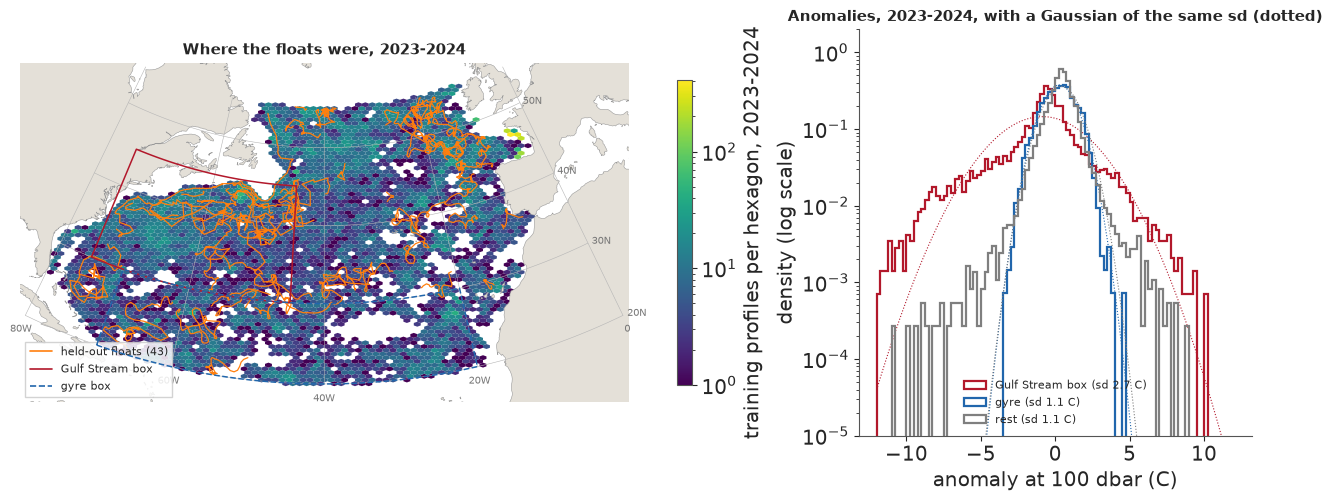

In [4]:
R_EARTH = 6371.0
PHI1, PHI2, PHI0, LAM0 = np.radians([30.0, 50.0, 37.5, -40.0])
N_LCC = np.log(np.cos(PHI1) / np.cos(PHI2)) / np.log(np.tan(np.pi / 4 + PHI2 / 2) / np.tan(np.pi / 4 + PHI1 / 2))
F_LCC = np.cos(PHI1) * np.tan(np.pi / 4 + PHI1 / 2) ** N_LCC / N_LCC
RHO0 = F_LCC / np.tan(np.pi / 4 + PHI0 / 2) ** N_LCC


def lcc(lat, lon):
    """Lambert conformal conic, km: standard parallels 30N and 50N, origin 37.5N 40W."""
    phi, lam = np.radians(np.asarray(lat, float)), np.radians(np.asarray(lon, float))
    rho = F_LCC / np.tan(np.pi / 4 + phi / 2) ** N_LCC
    theta = N_LCC * (lam - LAM0)
    return R_EARTH * rho * np.sin(theta), R_EARTH * (RHO0 - rho * np.cos(theta))


with np.load(data.path("natural_earth_50m_land_natl"), allow_pickle=False) as rings:
    LAND = [np.c_[lcc(r[:, 1], r[:, 0])] for r in (rings[k] for k in rings.files)]
EDGE_LAT = np.r_[np.full(81, 20.0), np.linspace(20, 55, 71), np.full(81, 55.0), np.linspace(55, 20, 71)]
EDGE_LON = np.r_[np.linspace(-80, 0, 81), np.zeros(71), np.linspace(0, -80, 81), np.full(71, -80.0)]
EX, EY = lcc(EDGE_LAT, EDGE_LON)


def outline(ax, box, **kw):
    la = np.r_[np.full(30, box["lat"][0]), np.linspace(*box["lat"], 20), np.full(30, box["lat"][1]),
               np.linspace(*box["lat"][::-1], 20)]
    lo = np.r_[np.linspace(*box["lon"], 30), np.full(20, box["lon"][1]), np.linspace(*box["lon"][::-1], 30),
               np.full(20, box["lon"][0])]
    ax.plot(*lcc(la, lo), **kw)


def basemap(ax, labels=True, boxes=True):
    ax.add_collection(PolyCollection(LAND, facecolor="#e4e0d8", edgecolor="#9a9a9a", lw=0.4, zorder=3))
    for lat in (20, 30, 40, 50):
        ax.plot(*lcc(np.full(81, lat), np.linspace(-80, 0, 81)), color="#b5b5b5", lw=0.4, zorder=4)
        if labels:
            ax.text(*lcc(lat, 0.6), f"{lat}N", fontsize=7, color="#777777", va="center", zorder=5)
    for lon in (-80, -60, -40, -20, 0):
        ax.plot(*lcc(np.linspace(20, 55, 36), np.full(36, lon)), color="#b5b5b5", lw=0.4, zorder=4)
        if labels:
            ax.text(*lcc(18.8, lon), f"{-lon}W" if lon else "0", fontsize=7, color="#777777", ha="center",
                    va="top", zorder=5)
    if boxes:
        outline(ax, GULF, color="#b2182b", lw=1.1, zorder=6)
        outline(ax, GYRE, color="#2166ac", lw=1.1, ls="--", zorder=6)
    ax.set_xlim(EX.min() - 80, EX.max() + 80)
    ax.set_ylim(EY.min() - 260, EY.max() + 60)
    ax.set_aspect("equal")
    ax.set_axis_off()


def gridded(lat_c, lon_c, values, step):
    """Cell values on a regular grid of `step` degrees as projected corners and a masked field."""
    la = np.arange(20 + step / 2, 55, step)
    lo = np.arange(-80 + step / 2, 0, step)
    field = np.full((len(la), len(lo)), np.nan)
    field[np.round((np.asarray(lat_c) - la[0]) / step).astype(int),
          np.round((np.asarray(lon_c) - lo[0]) / step).astype(int)] = values
    LA, LO = np.meshgrid(np.r_[la - step / 2, la[-1] + step / 2], np.r_[lo - step / 2, lo[-1] + step / 2],
                         indexing="ij")
    return (*lcc(LA, LO), np.ma.masked_invalid(field))


fig, (left, right) = plt.subplots(1, 2, figsize=(12.5, 4.9), width_ratios=(1.55, 1))
px, py = lcc(train["lat"], train["lon"])
hb = left.hexbin(px, py, gridsize=70, bins="log", mincnt=1, cmap="viridis", lw=0, zorder=2)
for _, f in test.groupby("float_id"):
    left.plot(*lcc(f["lat"], f["lon"]), color="#ff7f0e", lw=0.9, zorder=5)
basemap(left)
fig.colorbar(hb, ax=left, shrink=0.75, label="training profiles per hexagon, 2023-2024")
left.legend(handles=[Line2D([], [], color="#ff7f0e", lw=1.2, label="held-out floats (43)"),
                     Line2D([], [], color="#b2182b", lw=1.2, label="Gulf Stream box"),
                     Line2D([], [], color="#2166ac", lw=1.2, ls="--", label="gyre box")],
            loc="lower left", fontsize=8, frameon=True, facecolor="white", framealpha=0.85)
left.set_title("Where the floats were, 2023-2024", fontsize=11)
bins = np.linspace(-12, 12, 97)
for r, colour in ((0, "#b2182b"), (1, "#2166ac"), (2, "#7f7f7f")):
    sub = fit_years["anom"][fit_years["region"] == r]
    right.hist(sub, bins=bins, density=True, histtype="step", lw=1.6, color=colour, label=f"{REGIONS[r]} (sd {sub.std():.1f} C)")
    right.plot(bins, stats.norm.pdf(bins, sub.mean(), sub.std()), color=colour, lw=0.8, ls=":")
right.set(yscale="log", ylim=(1e-5, 2), xlabel="anomaly at 100 dbar (C)", ylabel="density (log scale)")
right.set_title("Anomalies, 2023-2024, with a Gaussian of the same sd (dotted)", fontsize=11)
right.legend(fontsize=8, frameon=False);

The floats cover the basin unevenly, with holes in mid-basin and along the African coast, and the
held-out floats (orange) sample every part of it. On the right, the log scale shows what the sd hides: in the
Gulf Stream box the anomalies have tails that a Gaussian of the same sd puts at essentially zero probability.
A Gaussian stationary model must choose one variance for the whole basin, too small at the front and too
large in the gyre. That is the first failure we expect; part 7 tests for it.

## 2 · How far a float drifts

A launch site is only where a track begins. We take every run of 36 consecutive cycles (a year of 10-day
cycles) in the training floats, starting a new run every 12 cycles, and move each to a common origin.

19,410 cycle-to-cycle steps: median 40 km, 90th percentile 101 km; in the Gulf Stream box median 64 km, 90th percentile 157 km
588 one-year tracks: net displacement median 376 km (627 km for the 133 starting in the box, 337 km elsewhere); 90th percentile 926 km


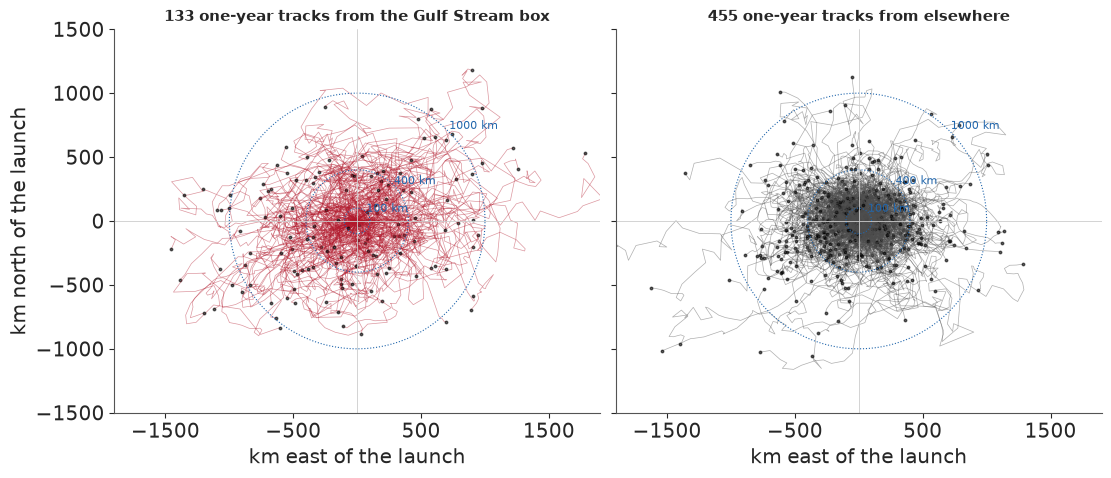

In [5]:
def year_tracks(frame, n_cyc=36, every=12):
    """Runs of n_cyc consecutive 5-15 day cycles: start (lat, lon), steps (km east, km north), day gaps."""
    starts, steps, gaps, one_step = [], [], [], []
    for _, f in frame.sort_values(["float_id", "t_days"]).groupby("float_id"):
        cyc, t, la, lo = (f[k].to_numpy() for k in ("cycle", "t_days", "lat", "lon"))
        mid = np.radians(0.5 * (la[1:] + la[:-1]))
        dx, dy = np.diff(lo) * 111.19 * np.cos(mid), np.diff(la) * 111.19
        ok = (np.diff(cyc) == 1) & (np.diff(t) > 5) & (np.diff(t) < 15)
        one_step.append(np.c_[np.hypot(dx, dy), la[:-1], lo[:-1]][ok])
        run = 0
        for i in range(len(ok)):
            run = run + 1 if ok[i] else 0
            if run >= n_cyc - 1 and (run - (n_cyc - 1)) % every == 0:
                s = i + 1 - (n_cyc - 1)
                starts.append((la[s], lo[s]))
                steps.append(np.c_[dx[s:i + 1], dy[s:i + 1]])
                gaps.append(np.diff(t[s:i + 2]))
    one_step = np.concatenate(one_step)
    return np.array(starts), np.array(steps), np.array(gaps), one_step[:, 0], one_step[:, 1], one_step[:, 2]


starts, steps, gaps, step_km, step_lat, step_lon = year_tracks(train)
assert len(starts) == store.load_json("design_inputs")["n_tracks"]  # the tracks the design drew from
gs_step = in_box(step_lat, step_lon, GULF)
net = np.hypot(*steps.sum(axis=1).T)
gs_start = in_box(starts[:, 0], starts[:, 1], GULF)
print(f"{len(step_km):,} cycle-to-cycle steps: median {np.median(step_km):.0f} km, 90th percentile "
      f"{np.quantile(step_km, 0.9):.0f} km; in the Gulf Stream box median {np.median(step_km[gs_step]):.0f} km, "
      f"90th percentile {np.quantile(step_km[gs_step], 0.9):.0f} km")
print(f"{len(starts)} one-year tracks: net displacement median {np.median(net):.0f} km "
      f"({np.median(net[gs_start]):.0f} km for the {gs_start.sum()} starting in the box, "
      f"{np.median(net[~gs_start]):.0f} km elsewhere); 90th percentile {np.quantile(net, 0.9):.0f} km")

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, mask, title in ((axes[0], gs_start, "from the Gulf Stream box"), (axes[1], ~gs_start, "from elsewhere")):
    for k in np.flatnonzero(mask):
        path = np.vstack([[0, 0], np.cumsum(steps[k], axis=0)])
        ax.plot(path[:, 0], path[:, 1], lw=0.5, alpha=0.45, color="#b2182b" if ax is axes[0] else "#4d4d4d")
        ax.plot(*path[-1], "o", ms=1.8, color="black", alpha=0.6)
    for radius in (100, 400, 1000):
        circle = np.linspace(0, 2 * np.pi, 200)
        ax.plot(radius * np.cos(circle), radius * np.sin(circle), color="#2166ac", lw=0.8, ls=":")
        ax.text(radius * 0.72, radius * 0.72, f"{radius} km", fontsize=8, color="#2166ac")
    ax.set(xlabel="km east of the launch", aspect="equal")
    ax.set_title(f"{mask.sum()} one-year tracks {title}", fontsize=11)
    ax.axhline(0, color="#cccccc", lw=0.6)
    ax.axvline(0, color="#cccccc", lw=0.6)
axes[0].set(ylabel="km north of the launch", xlim=(-1900, 1900), ylim=(-1500, 1500), xticks=[-1500, -500, 500, 1500]);

A float moves about 40 km per cycle at the median and 100 km at the 90th percentile, and half again as much
in the Gulf Stream box. After a year the typical float is almost 400 km from its launch; one launched in the
box ends a median 630 km away, and some more than 1,500 km. The mesoscale field decorrelates over about 100 km
and a month (part 4), so a launch site is a cloud far wider than the features it is meant to sample. The
design in part 9 therefore launches each candidate float along a real track: one of the 588 tracks that
started within 600 km, picked at random and replayed from the site until it would run aground or leave the
box. Four such drift replicates, the same for every rule compared, stand in for the drift nobody can predict.

## 3 · The model, and what it costs

The anomaly $y_i$ at position $(x_i, y_i)$ and day $t_i$ is a Gaussian process plus noise,

$$y = f(x, y, t) + h(t)^\top \beta + \varepsilon, \qquad \varepsilon \sim N(0, s_n^2),$$

with a mesoscale term and a basin-scale term in the covariance,

$$k = s_1^2\, M(r_1) + s_2^2\, M(r_2), \qquad
  r_1^2 = \Big(\frac{\Delta x - c\,\Delta t}{\ell_{x1}}\Big)^2 + \Big(\frac{\Delta y}{\ell_{y1}}\Big)^2
  + \Big(\frac{\Delta t}{\ell_{t1}}\Big)^2,$$

and $r_2$ the same with its own lengthscales and no drift. $M(r) = e^{-r}$ is the Matern 1/2 (exponential)
kernel, the one Kuusela & Stein used. The speed $c$ lets the mesoscale pattern travel: eddies and Rossby
waves in the North Atlantic move west at a few km a day. An intercept and a trend $h(t) = (1, t)$ with
Normal(0, 1) coefficients are integrated out, adding $H B H^\top$ to the covariance, because 2023-2025 are
not centred on the 2015-2022 climatology. Coordinates are Mercator kilometres, so a stationary kernel has
physical scales that shrink with $\cos(\text{latitude})$. The nine scales get LogNormal priors (medians 1 C,
300 km, 200 km, 15 days, 0.5 C, 1,500 km, 1,000 km, 200 days, and 0.3 C for the nugget; log sd 0.75) and
$c$ a Normal(0, 5 km/day): E86 showed how a half-normal tail lets a scale run away. Kernel and coordinates
were chosen on a small crop before the full run, by held-out log score on 16 floats: Matern 3/2 scored 10 nats
worse, within twice its standard error, so the simpler kernel stayed, and Mercator beat equirectangular by
3.4 nats at 2.5 standard errors, a fragile call on so few floats.

The log density is $-\tfrac12 y^\top K^{-1} y - \tfrac12 \log|K| - \tfrac n2 \log 2\pi$, and its gradient
for each hyperparameter is $\tfrac12 \operatorname{tr}\big((\alpha\alpha^\top - K^{-1})\,\partial K/
\partial\theta_j\big)$ with $\alpha = K^{-1}y$. Automatic differentiation through the factor would keep
several 23,939 x 23,939 matrices alive, so the stored run builds $K$ in blocks of 1,024 rows and sums the trace
block by block. In PyMC the model is a few lines, and it is what the NUTS check of part 4 sampled. We build it
on a 400-profile subset of the crop and check its log density against a plain NumPy version of the kernel.

In [6]:
PRIOR_MEDIAN = np.array([1.0, 300.0, 200.0, 15.0, 0.5, 1500.0, 1000.0, 200.0, 0.3, 0.0])
PRIOR_MU, PRIOR_SD = np.r_[np.log(PRIOR_MEDIAN[:9]), 0.0], np.r_[np.full(9, 0.75), 5.0]
NAMES = ["log_s1", "log_lx1", "log_ly1", "log_lt1", "log_s2", "log_lx2", "log_ly2", "log_lt2", "log_sn", "c"]


def mercator(lat, lon, t):
    lam, phi = np.radians(np.asarray(lon, float)), np.radians(np.asarray(lat, float))
    return np.c_[R_EARTH * lam, R_EARTH * np.log(np.tan(np.pi / 4 + phi / 2)), np.asarray(t, float)]


def kernel(Xa, Xb, theta, nu=0.5, dtype=np.float64):
    """The run's covariance between point sets, in `dtype` arithmetic, without the nugget or the trend."""
    Xa, Xb, theta = Xa.astype(dtype), Xb.astype(dtype), np.asarray(theta, dtype)
    e, c = np.exp(theta[:9]), theta[9]
    dx = Xa[:, None, 0] - Xb[None, :, 0]
    dy = Xa[:, None, 1] - Xb[None, :, 1]
    dt = Xa[:, None, 2] - Xb[None, :, 2]
    r1 = ((dx - c * dt) / e[1]) ** 2 + (dy / e[2]) ** 2 + (dt / e[3]) ** 2
    r2 = (dx / e[5]) ** 2 + (dy / e[6]) ** 2 + (dt / e[7]) ** 2
    shape = (lambda q: np.exp(-np.sqrt(q))) if nu == 0.5 else (lambda q: np.exp(-q / 2))  # Matern 1/2 or ExpQuad
    return e[0] ** 2 * shape(r1) + e[4] ** 2 * shape(r2)


def full_cov(X, theta, nu=0.5, dtype=np.float64):
    t = X[:, 2].astype(dtype) / dtype(365.25)
    K = kernel(X, X, theta, nu, dtype) + (dtype(1.0) + np.outer(t, t))  # integrated intercept and trend
    K[np.diag_indices_from(K)] += dtype(np.exp(2 * theta[8]))
    return K


crop = argo[(argo["year"] == 2024) & in_box(argo["lat"], argo["lon"], dict(lat=(25.0, 45.0), lon=(-75.0, -40.0)))]
crop = crop.iloc[np.sort(np.random.default_rng(7).permutation(len(crop))[:400])]
X400, y400 = mercator(crop["lat"], crop["lon"], crop["t_days"]), crop["anom"].to_numpy()

with pm.Model() as audit_model:
    theta = pm.Normal("theta", mu=PRIOR_MU, sigma=PRIOR_SD, shape=10)
    e = pt.exp(theta[:9])
    Xc = pt.as_tensor_variable(X400)
    dx, dy, dt = (Xc[:, None, j] - Xc[None, :, j] for j in range(3))
    r1 = ((dx - theta[9] * dt) / e[1]) ** 2 + (dy / e[2]) ** 2 + (dt / e[3]) ** 2
    r2 = (dx / e[5]) ** 2 + (dy / e[6]) ** 2 + (dt / e[7]) ** 2
    t_years = X400[:, 2] / 365.25
    K = (e[0] ** 2 * pt.exp(-pt.sqrt(r1 + 1e-12)) + e[4] ** 2 * pt.exp(-pt.sqrt(r2 + 1e-12))
         + e[8] ** 2 * pt.eye(len(y400)) + (1.0 + np.outer(t_years, t_years)))
    pm.MvNormal("y", mu=np.zeros(len(y400)), cov=K, observed=y400)

check_theta = np.asarray(scores["pymc_audit"]["2000"]["laplace_mode"])  # any value will do; this one is real
t0 = time.perf_counter()
logp_fn, dlogp_fn = audit_model.compile_logp(), audit_model.compile_dlogp()
lp_pymc = float(logp_fn({"theta": check_theta}))
dlogp_fn({"theta": check_theta})  # the first call compiles
compile_s = time.perf_counter() - t0
L400 = np.linalg.cholesky(full_cov(X400, check_theta))
z400 = np.linalg.solve(L400, y400)
lp_numpy = (-0.5 * z400 @ z400 - np.log(np.diag(L400)).sum() - 0.5 * len(y400) * np.log(2 * np.pi)
            + stats.norm.logpdf(check_theta, PRIOR_MU, PRIOR_SD).sum())
t0 = time.perf_counter()
for _ in range(20):
    dlogp_fn({"theta": check_theta})
grad_ms = (time.perf_counter() - t0) / 20 * 1e3
print(f"n = {len(y400)}: PyMC log density {lp_pymc:.3f}, NumPy {lp_numpy:.3f}, difference {lp_pymc - lp_numpy:.1e}")
print(f"Compiling took {compile_s:.0f} s here; one gradient {grad_ms:.0f} ms on {CORES} cores "
      f"(the stored run measured 16.7 ms at n = 400, 98 ms at 800 and 1,037 ms at 2,000 on one thread)")

n = 400: PyMC log density -850.797, NumPy -850.797, difference 8.2e-05
Compiling took 22 s here; one gradient 16 ms on 2 cores (the stored run measured 16.7 ms at n = 400, 98 ms at 800 and 1,037 ms at 2,000 on one thread)


The PyMC graph and the NumPy kernel agree to the last few digits (the PyMC version adds $10^{-12}$ inside the
square root to keep its gradient finite at zero distance). A gradient takes tens of milliseconds at n = 400,
but PyMC builds the whole n x n kernel algebra in its graph, and the stored run measured about one second at
n = 2,000, 60 times the cost at n = 400 for 5 times the data. That is why NUTS can check the model only on subsets, and why the full fit is a hand-written
JAX function on a GPU.

How much does exactness cost on this machine's hardware? The stored price ladder timed the log density with
its gradient at n = 2,000 to 20,000 on three routes, each in a fresh process: the GPU in float32, the GPU in
float64, and JAX on 15 CPU threads in float64. Solid markers are measured; hollow ones are the $n^3$
extrapolation to the full 23,939, and the stars are what the stored run actually paid per evaluation at full
size, overheads included.

GPU, float32               n = 20,000:   0.92 s measured; n = 23,939:    1.6 s extrapolated, 1.7 s paid per evaluation in the run
GPU, float64               n = 20,000:  33.35 s measured; n = 23,939:   57.2 s extrapolated, 57.5 s paid per evaluation in the run
CPU, 15 threads, float64   n = 20,000:  48.28 s measured; n = 23,939:   82.8 s extrapolated


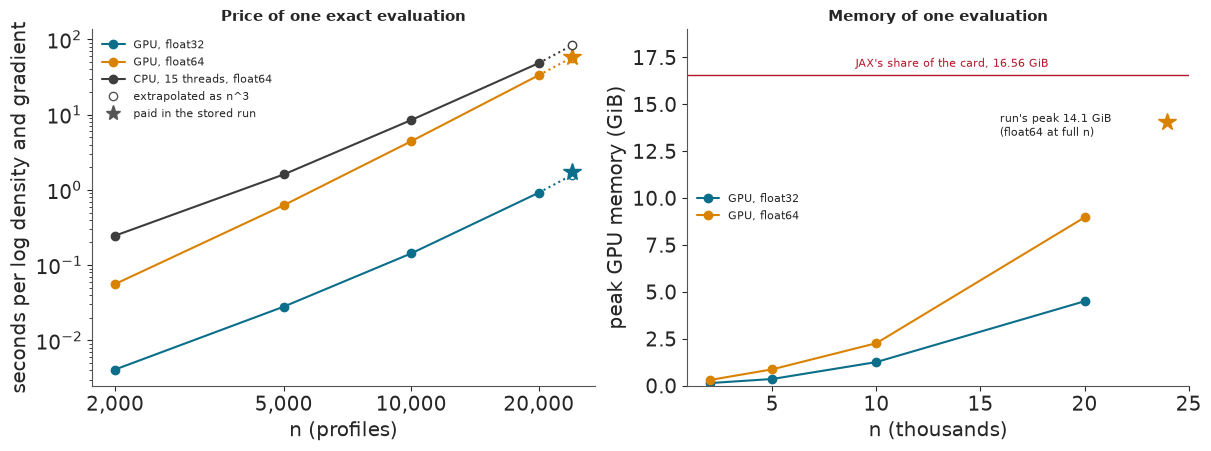

In [7]:
N_FULL = 23_939
ladder_n = np.array([2000, 5000, 10000, 20000])
routes = {"gpu_f32_vg": ("GPU, float32", "#0b6e8a"), "gpu_f64_vg": ("GPU, float64", "#d98200"),
          "cpu_f64_vg": ("CPU, 15 threads, float64", "#3d3d3d")}
walls, fits = scores["walls_s"], scores["fits"]
paid = {"gpu_f32_vg": walls["fit_A_f32"] / fits["fit_A_f32"]["evaluations"],
        "gpu_f64_vg": walls["fit_A_f64"] / fits["fit_A_f64"]["evaluations"]}
fig, (ax, mem) = plt.subplots(1, 2, figsize=(12, 4.4))
for key, (label, colour) in routes.items():
    secs = np.array([p3["table"][f"{key}_{n}"]["s"] for n in ladder_n])
    ax.plot(ladder_n, secs, "o-", color=colour, label=label)
    projected = secs[-1] * (N_FULL / 20000) ** 3
    ax.plot([20000, N_FULL], [secs[-1], projected], ":", color=colour)
    ax.plot(N_FULL, projected, "o", mfc="white", color=colour)
    if key in paid:
        ax.plot(N_FULL, paid[key], "*", ms=13, color=colour)
    print(f"{label:26s} n = 20,000: {secs[-1]:6.2f} s measured; n = {N_FULL:,}: {projected:6.1f} s extrapolated"
          + (f", {paid[key]:.1f} s paid per evaluation in the run" if key in paid else ""))
ax.set(xscale="log", yscale="log", xlabel="n (profiles)", ylabel="seconds per log density and gradient")
ax.set_xticks([2000, 5000, 10000, 20000], ["2,000", "5,000", "10,000", "20,000"], minor=False)
ax.set_xticks([], minor=True)
ax.set_title("Price of one exact evaluation", fontsize=11)
ax.legend(handles=ax.get_legend_handles_labels()[0] + [
    Line2D([], [], marker="o", ls="", mfc="white", color="#555555", label="extrapolated as n^3"),
    Line2D([], [], marker="*", ms=11, ls="", color="#555555", label="paid in the stored run")], fontsize=8, frameon=False)
for key, (label, colour) in list(routes.items())[:2]:
    peaks = np.array([p3["table"][f"{key}_{n}"]["peak_gib"] for n in ladder_n])
    mem.plot(ladder_n / 1e3, peaks, "o-", color=colour, label=label)
mem.axhline(16.56, color="#b2182b", lw=1)
mem.text(9, 17.0, "JAX's share of the card, 16.56 GiB", color="#b2182b", fontsize=8)
mem.plot(N_FULL / 1e3, scores["peak_vram_gib"], "*", ms=13, color="#d98200")
mem.annotate(f"run's peak {scores['peak_vram_gib']:.1f} GiB\n(float64 at full n)", (N_FULL / 1e3, scores["peak_vram_gib"]),
             xytext=(-120, -10), textcoords="offset points", fontsize=8)
mem.set(xlabel="n (thousands)", ylabel="peak GPU memory (GiB)", ylim=(0, 19))
mem.set_title("Memory of one evaluation", fontsize=11)
mem.legend(fontsize=8, frameon=False, loc="center left");

Three things stand out. The GPU in float32 is in a class of its own: under a second at n = 20,000, 36 to 53
times faster than the two float64 routes. The GPU in float64 is only a little faster than 15 CPU cores, so on
this card double precision is mainly a memory question. And the cost grows as $n^3$: at full size one float32
evaluation cost 1.7 s in the run and one float64 evaluation 57 s, close to the extrapolation. The run's
peak, 14.1 GiB of the card's usable 16.6, was a float64 gradient at full n, and only after the matrix was
handed to the Cholesky routine in a careful order (the first attempt asked for 17 GiB). Twice the data would
need eight times the time and four times the memory, which this card does not have.

## 4 · Where the fit lands

The stored run found the posterior mode by L-BFGS, first in float32 (76 evaluations), then in float64 for the
last steps (25 evaluations), because part 8 shows that float32 gradients are too noisy near the mode for a
finite-difference Hessian. It then took the Hessian by central differences of the exact gradient (20 float64
gradients, 19 minutes), drew 64 scrambled Sobol points from the resulting Gaussian, and reweighted them by
Pareto-smoothed importance sampling (Vehtari et al. 2024) against the exact log density. The table shows the
modes of the four exact or near-exact models, with the prior's 1% and 99% quantiles beside them.

In [8]:
def natural(theta):
    theta = np.asarray(theta, float)
    return np.r_[np.exp(theta[..., :9]), theta[..., 9]]


units = ["s1 (C)", "lx1 (km)", "ly1 (km)", "lt1 (days)", "s2 (C)", "lx2 (km)", "ly2 (km)", "lt2 (days)",
         "sn (C)", "c (km/day)"]
z99 = stats.norm.ppf(0.99)
table = pd.DataFrame({
    "prior 1%": natural(PRIOR_MU - z99 * PRIOR_SD), "prior 99%": natural(PRIOR_MU + z99 * PRIOR_SD),
    "A": natural(fits["fit_A_f64"]["theta"]), "A-t": natural(fits["fit_At_final"]["theta"]),
    "C (Vecchia)": natural(fits["fit_C"]["theta"]), "A'": natural(fits["fit_Afix_f64"]["theta"]),
    "B: median of 79 windows": np.median([natural(t) for t in pack["B_theta"]], axis=0)}, index=units)
print(table.map(lambda v: f"{v:,.3g}").to_string())
hess = scores["hessian"]
print(f"\nHessian at A's mode: negative definite, eigenvalues {hess['eigen'][0]:,.0f} to {hess['eigen'][-1]:.1f}; "
      f"Laplace sd of log sn {hess['sd'][8]:.2f}, of log s1 {hess['sd'][0]:.3f}")
sob = scores["sobol"]
print(f"PSIS on 64 Sobol points: Pareto k = {sob['pareto_k']:.2f}, effective sample size {sob['ess']:.0f} of 64")
b_sn = np.exp(pack["B_theta"][:, 8])
print(f"Nugget sd in the 79 windows: median {np.median(b_sn):.2f} C (range {b_sn.min():.3f}-{b_sn.max():.2f}); "
      f"{scores['fit_B']['edges_any']} windows have some hyperparameter beyond its prior's 1-99% range")

           prior 1% prior 99%         A       A-t C (Vecchia)        A' B: median of 79 windows
s1 (C)        0.175      5.72      1.46      1.46        1.48         1                    0.85
lx1 (km)       52.4  1.72e+03        95      95.4        95.9       101                     126
ly1 (km)       34.9  1.14e+03      90.6      90.8          96      94.9                     119
lt1 (days)     2.62      85.9      31.1      31.1        32.7        25                    34.1
s2 (C)       0.0873      2.86     0.784     0.782       0.521     0.667                   0.503
lx2 (km)        262  8.59e+03  1.58e+03  1.58e+03    3.05e+03       847                     801
ly2 (km)        175  5.72e+03       657       658         254       692                     529
lt2 (days)     34.9  1.14e+03       993       994         495  1.07e+03                     479
sn (C)       0.0524      1.72    0.0141    0.0141       0.017   0.00661                   0.217
c (km/day)    -11.6      11.6     -0.68 

Most of the fit is physically sensible. The mesoscale term has an sd of 1.5 C, a lengthscale of 95 km (in
Mercator km; about 75 km on the ground at 37N) and a month in time, and it drifts west at 0.7 km a day. The
basin-scale term has an sd of 0.8 C, scales of 1,600 km east-west and 660 km north-south, and almost three
years in time: slow change that a 2015-2022 climatology cannot know about. The
Vecchia fit lands close on the mesoscale term and wanders on the basin term, which a 30-neighbour
approximation sees only weakly.

**Failure: the nugget sits at its prior's edge.** The noise sd comes out at 0.014 C, below the prior's 1%
quantile of 0.05 C, and every exact fit we made (A, A', and each with a Student-t nugget) put it between
0.007 and 0.014 C. A float's thermistor is good to about 0.002 C, but 0.014 C is not a plausible sd for
everything the field does not explain, and the local windows put it at about 0.2 C. The rough Matern 1/2
mesoscale term, at 95 km and a month, can pass through nearly every profile at basin density, so the data
cannot tell measurement noise from the field's own small-scale variance, and the likelihood calls all of it
field. A nugget at its edge might also have meant that frontal outliers were being absorbed, and a Student-t
nugget, which can downweight them, was the planned remedy. Its weights stayed at one: there was
nothing left for the noise term to explain. We kept the model with this caveat. It matters because a Laplace
approximation is least trustworthy at an edge, and the PSIS check agrees: a Pareto k of 0.76 is above the 0.7
at which importance weights become unreliable, so the ten parameter draws used in the design are simply the
first ten Sobol points, unweighted.

**The NUTS check.** NUTS cannot check the Laplace approximation at 23,939 points, so the stored run sampled
the same model with nutpie (4 chains, 1,000 warm-up and 1,000 draws) on random subsets of 800 and 2,000
profiles from the crop, and compared each posterior with a Laplace fit to the same subset. We count the
agreement as good if every Laplace mode is within half a posterior sd of the NUTS mean, every sd ratio is in
0.7-1.3 and $\hat R$ is at most 1.01.

   n parameter  Laplace mode  NUTS mean      z  sd ratio  r_hat  ESS bulk
 800    log_s1         0.197      0.135 -0.150     0.500  1.097    29.095
 800   log_lx1         4.476      5.055  0.607     0.493  1.065    49.608
 800    log_sn         0.395      0.232 -0.273     0.219  1.095    31.656
 800         c        -3.856     -4.038 -0.055     0.176  1.012   438.474
2000    log_s1         0.643      0.637 -0.141     0.890  1.007  1102.018
2000   log_lx1         4.399      4.345 -0.241     0.926  1.002  1190.298
2000    log_sn        -0.711     -1.003 -0.546     0.650  1.003   888.327
2000         c         0.069      0.051 -0.025     0.952  1.002  2845.034
n = 800: max r_hat 1.097, min bulk ESS 29, 3 divergences, chains 0.65-0.76 h each; where they disagree: log_s1, log_lx1, log_lt1, log_s2, log_sn, c
n = 2000: max r_hat 1.009, min bulk ESS 888, 6 divergences, chains 6.08-6.27 h each; where they disagree: log_sn


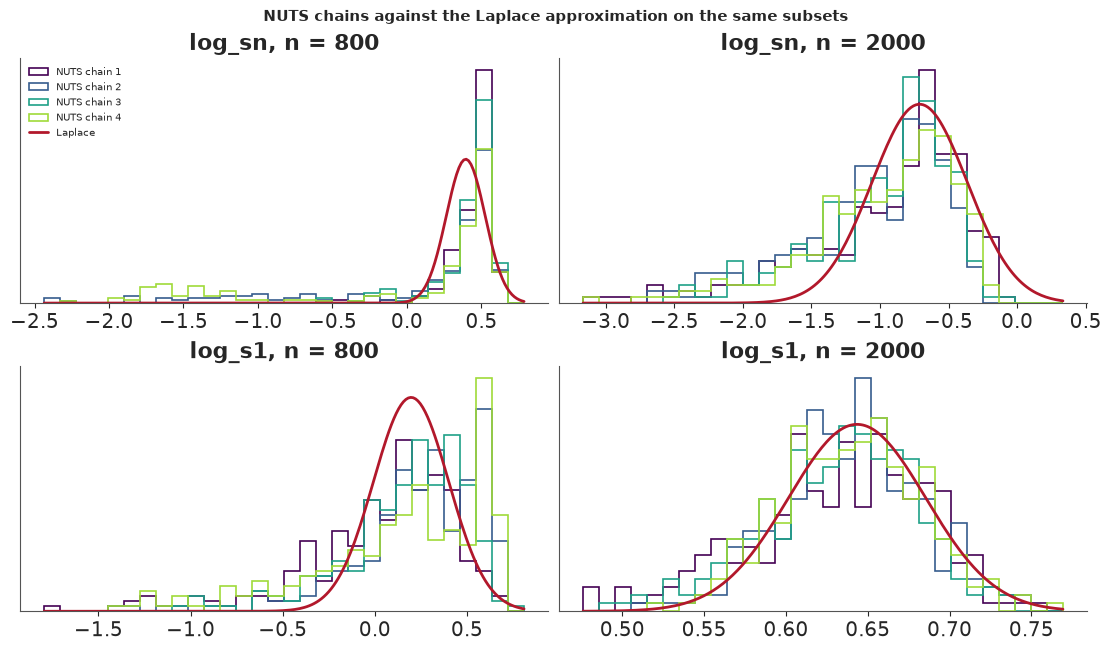

In [9]:
audit = scores["pymc_audit"]
rows = []
for n in ("800", "2000"):
    a_ = audit[n]
    for j in (0, 1, 8, 9):
        rows.append({"n": int(n), "parameter": NAMES[j], "Laplace mode": a_["laplace_mode"][j], "NUTS mean": a_["nuts_mean"][j],
                     "z": a_["z_mode_vs_mean"][j], "sd ratio": a_["sd_ratio_laplace_over_nuts"][j],
                     "r_hat": a_["rhat"][j], "ESS bulk": a_["ess_bulk"][j]})
print(pd.DataFrame(rows).round(3).to_string(index=False))
for n in ("800", "2000"):
    a_ = audit[n]
    print(f"n = {n}: max r_hat {a_['max_rhat']:.3f}, min bulk ESS {a_['min_ess_bulk']:.0f}, {a_['divergences']} divergences, "
          f"chains {min(a_['chain_wall_s']) / 3600:.2f}-{max(a_['chain_wall_s']) / 3600:.2f} h each; "
          f"where they disagree: {', '.join(a_['failing_coordinates'])}")

fig, axes = plt.subplots(2, 2, figsize=(11, 6.4))
chain_of = np.arange(1000) // 250  # the stored draws are every 4th of 4 x 1,000, chain by chain
for col, n in enumerate(("800", "2000")):
    draws, a_ = pack[f"audit_draws_{n}"], audit[n]
    for row, j in enumerate((8, 0)):
        ax = axes[row, col]
        lo_, hi_ = np.quantile(draws[:, j], [0.001, 0.999])
        grid = np.linspace(min(lo_, a_["laplace_mode"][j] - 3 * a_["laplace_sd"][j]),
                           max(hi_, a_["laplace_mode"][j] + 3 * a_["laplace_sd"][j]), 200)
        for k in range(4):
            ax.hist(draws[chain_of == k, j], bins=30, range=(grid[0], grid[-1]), density=True, histtype="step",
                    lw=1.2, color=plt.cm.viridis(k / 3.5), label=f"NUTS chain {k + 1}")
        ax.plot(grid, stats.norm.pdf(grid, a_["laplace_mode"][j], a_["laplace_sd"][j]), color="#b2182b", lw=2,
                label="Laplace")
        ax.set(title=f"{NAMES[j]}, n = {n}", yticks=[])
axes[0, 0].legend(fontsize=7, frameon=False)
fig.suptitle("NUTS chains against the Laplace approximation on the same subsets", fontsize=11);

At n = 800 NUTS and Laplace disagree on every count, and the figure shows why. The posterior of the log nugget has a
peak near the Laplace mode and a long tail towards much smaller nuggets, and the four chains visit that tail
unequally; the mesoscale amplitude is skewed the other way, because a smaller nugget needs a larger field
to explain the same variance. It is the trade-off the full fit resolved by pushing the nugget to its edge.
With 800 points the posterior is a curved ridge, $\hat R$ reaches 1.10 with bulk ESS as low as 29, and a
Gaussian at the mode is far too narrow along it (sd ratios down to 0.2). At n = 2,000 the chains mix
($\hat R$ 1.009, bulk ESS at least 888, 6 divergences in 4,000 draws), and Laplace matches NUTS on nine of
the ten coordinates. The tenth is the nugget: the Laplace mode is 0.55 posterior sd from the NUTS mean, just
beyond half a sd, and its sd is 0.65 of the NUTS sd. So the two agree on everything but the nugget, which
tells the same story as the full fit from another direction: the full-scale uncertainty in the nugget is
approximate and probably too narrow, while the other nine look trustworthy at the scale we could test. The
chains took about 6 hours each, longer than the 4.6-6.1 hours we had extrapolated.

## 5 · What the map says

The posterior mean and sd of the latent anomaly field at the mode, on a one-degree grid for the middle of
September 2024, are below for the stationary model A, with A''s sd beside it. A' is the nonstationary
variant of part 7: the same kernel multiplied by an amplitude map that varies over the basin. Dots are the
training profiles within 15 days of the map's date.

Median posterior sd, A: Gulf Stream box 1.29 C, gyre 1.39 C; A': 1.52 C and 0.78 C


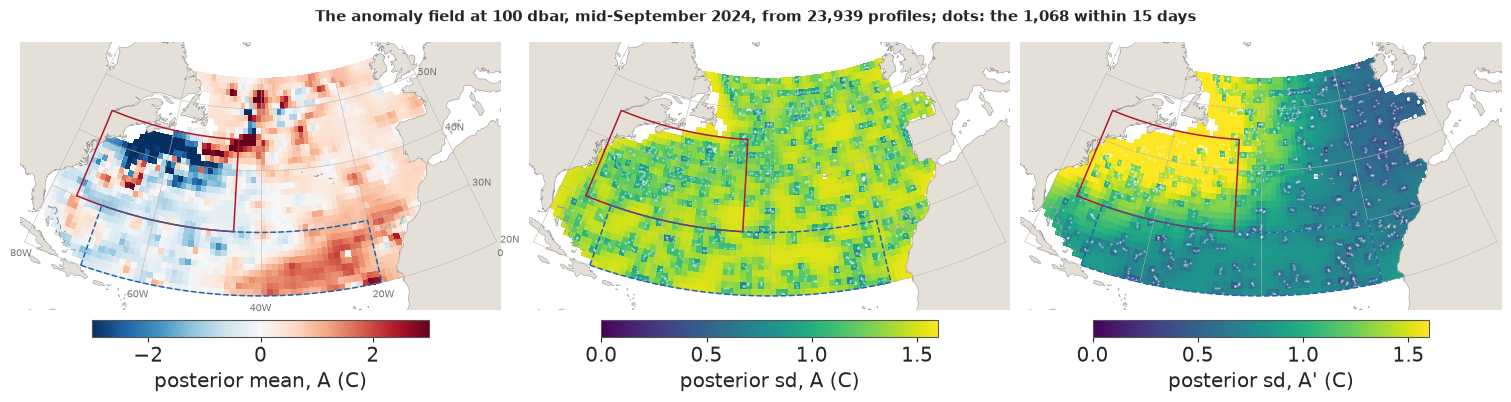

In [10]:
maps = store.load_json("replay")["maps"]
cell_lat, cell_lon, map_days = (np.asarray(maps[k]) for k in ("cell_lat", "cell_lon", "days"))
month = 8  # mid-September 2024
near = train[np.abs(train["t_days"] - map_days[month]) < 15]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
panels = [(pack["map_mean"][month], "posterior mean, A (C)", "RdBu_r", TwoSlopeNorm(0, -3, 3)),
          (pack["map_sd"][month], "posterior sd, A (C)", "viridis", plt.Normalize(0, 1.6)),
          (pack["map_sd_Afix"][month], "posterior sd, A' (C)", "viridis", plt.Normalize(0, 1.6))]
for ax, (values, title, cmap, norm) in zip(axes, panels):
    X, Y, field = gridded(cell_lat, cell_lon, values, 1.0)
    image = ax.pcolormesh(X, Y, field, cmap=cmap, norm=norm, shading="flat", zorder=1)
    if "sd" in title:
        ax.plot(*lcc(near["lat"], near["lon"]), ".", ms=1.0, color="white", alpha=0.5, zorder=5)
    basemap(ax, labels=ax is axes[0])
    fig.colorbar(image, ax=ax, shrink=0.7, orientation="horizontal", pad=0.02, label=title)
fig.suptitle(f"The anomaly field at 100 dbar, mid-September 2024, from {len(train):,} profiles; dots: the "
             f"{len(near):,} within 15 days", fontsize=11)
sd_A, sd_F = pack["map_sd"][month], pack["map_sd_Afix"][month]
gs_cells = in_box(cell_lat, cell_lon, GULF)
gy_cells = in_box(cell_lat, cell_lon, GYRE)
print(f"Median posterior sd, A: Gulf Stream box {np.median(sd_A[gs_cells]):.2f} C, gyre {np.median(sd_A[gy_cells]):.2f} C; "
      f"A': {np.median(sd_F[gs_cells]):.2f} C and {np.median(sd_F[gy_cells]):.2f} C");

The mean field shows both scales. In the Gulf Stream box a band of strong cold anomaly, 2-3 C, runs along
the northern side of the stream west of 50W, broken by warm patches a degree or two across: the stream's
meanders and eddies against a climatology that averages over them. The broad warm anomaly of the eastern
subtropics belongs to the slow term. The sd panels show what kind of model A is. Its uncertainty is
**geometry**: low on the dots, near its prior value of about 1.4 C a short way off, and the same function of
distance everywhere, because a stationary GP's posterior variance depends only on where the data are, never
on what they say. The calm gyre and the violent Gulf Stream look alike (median sd 1.39 C and 1.29 C). A'
puts its uncertainty where the ocean varies: 1.52 C in the box against 0.78 C in the gyre. Which is right is
a question for held-out data.

## 6 · Was exactness worth it?

Four racers are scored on the same 43 held-out floats:

- **A**, the exact stationary GP above;
- **B**, 79 local windows, each an exact GP of up to 4,000 profiles within 1,000 km of its centre with its
  own hyperparameters, a held-out float predicted by the window nearest its mean position;
- **C**, the Vecchia approximation with 30 neighbours in a maxmin ordering, fitted by its own likelihood,
  and predicting each float from the union of its profiles' 30 nearest training points;
- **A'**, exact again, with $K = D R D + s_n^2 I$, where $R$ is A's correlation structure and $D$ a smooth
  amplitude map built from B's windows, refitted at full size.

The score is the continuous ranked probability score (Gneiting & Raftery 2007), which for a Gaussian
predictive with mean $\mu$ and sd $\sigma$ is $\sigma\,[z(2\Phi(z) - 1) + 2\varphi(z) - 1/\sqrt\pi]$ with
$z = (y - \mu)/\sigma$: it rewards a sharp prediction that is right and punishes a confident one that is
wrong, in degrees C. We average it within each float, then over floats. We call one model better than
another only when the 90% interval of a paired bootstrap over whole floats (4,000 resamples) excludes zero,
over all floats and separately over those in the Gulf Stream box.

In [11]:
y_ho, float_ho, region_ho = pack["ho_y"], pack["ho_float"], pack["ho_region"]
MODELS = ("A", "B", "C", "Afix")


def per_float(values, mask=None):
    """Mean of `values` within each held-out float (only the profiles in `mask`), as a dict by float."""
    out = {}
    for k in np.unique(float_ho):
        m = (float_ho == k) if mask is None else (float_ho == k) & mask
        if m.any():
            out[k] = float(values[m].mean())
    return out


def paired_boot(base, rival, resamples=4000, seed=92):
    keys = sorted(set(base) & set(rival))
    diff = np.array([rival[k] - base[k] for k in keys])
    boots = diff[np.random.default_rng(seed).integers(0, len(diff), (resamples, len(diff)))].mean(axis=1)
    return diff.mean(), *np.quantile(boots, [0.05, 0.95]), len(diff)


crps = {m: pack[f"ho_{m}_crps"].astype(float) for m in LABEL}
rows, race = [], {}
for m in MODELS:
    row = {"model": LABEL[m], "CRPS (C)": np.mean(list(per_float(crps[m]).values())),
           "rmse (C)": np.sqrt(np.mean((y_ho - pack[f"ho_{m}_mean"]) ** 2))}
    for where, mask in (("all", None), ("Gulf Stream box", region_ho == 0), ("gyre", region_ho == 1), ("rest", region_ho == 2)):
        if m == "A":
            continue
        d, lo_, hi_, nf = paired_boot(per_float(crps["A"], mask), per_float(crps[m], mask))
        race[(m, where)] = (d, lo_, hi_, nf)
        call = "better" if hi_ < 0 else "worse" if lo_ > 0 else "no call"
        if where in ("all", "Gulf Stream box"):
            row[f"minus A, {where}"] = f"{d:+.3f} ({lo_:+.3f}, {hi_:+.3f}) {call}"
    rows.append(row)
print(pd.DataFrame(rows).round(3).fillna("").to_string(index=False))
for m in ("B", "C", "Afix"):
    print(f"{LABEL[m]:20s} minus A, gyre and rest: " + "; ".join(
        f"{w} {race[(m, w)][0]:+.3f} ({race[(m, w)][1]:+.3f}, {race[(m, w)][2]:+.3f})" for w in ("gyre", "rest")))
for (m, where), stored in (((m, w), scores["heldout"]["race"][m][key]) for m in ("B", "C", "Afix")
                           for w, key in (("all", "all"), ("Gulf Stream box", "gulf_stream"))):
    assert np.allclose(race[(m, where)][1:3], stored["ci90"], atol=1e-6)  # recomputed here = stored
print(f"\nFloats per region: {', '.join(f'{w} {race[('B', w)][3]}' for w in ('all', 'Gulf Stream box', 'gyre', 'rest'))}")
print(f"Log posterior at the mode: A' is {fits['fit_A_f64']['F'] - fits['fit_Afix_f64']['F']:,.0f} nats above A")

              model  CRPS (C)  rmse (C)                    minus A, all        minus A, Gulf Stream box
A, exact stationary     0.687     1.450                                                                
B, 79 local windows     0.631     1.447  -0.056 (-0.079, -0.035) better -0.054 (-0.105, +0.001) no call
  C, Vecchia m = 30     0.685     1.433 -0.003 (-0.015, +0.006) no call -0.011 (-0.045, +0.013) no call
  A', amplitude map     0.620     1.437  -0.067 (-0.084, -0.052) better  -0.062 (-0.100, -0.023) better
B, 79 local windows  minus A, gyre and rest: gyre -0.047 (-0.067, -0.028); rest -0.056 (-0.108, -0.010)
C, Vecchia m = 30    minus A, gyre and rest: gyre +0.003 (-0.002, +0.008); rest +0.019 (+0.002, +0.048)
A', amplitude map    minus A, gyre and rest: gyre -0.056 (-0.075, -0.038); rest -0.069 (-0.094, -0.046)

Floats per region: all 43, Gulf Stream box 16, gyre 9, rest 30
Log posterior at the mode: A' is 8,159 nats above A


**The exact fit did not beat the approximation.** On the same kernel, Vecchia's CRPS is 0.685 C against
exact A's 0.687 C, and the interval of the difference, $-0.015$ to $+0.006$, sits around zero over all floats
and in the Gulf Stream box, and its rmse is even slightly lower. This is the **screening effect** (Stein
2002): with a kernel like this, the 30 nearest profiles carry almost all the information about a point, and
the other 23,909 add nothing a forecaster would notice.

Both models that let the variance change over the basin beat A clearly: the windows B by 0.056 C and the
amplitude map A' by 0.067 C over all floats. In the box A' is better by 0.062 C, interval $-0.100$ to
$-0.023$; B's interval just touches zero there, so it gets no call. What does **not** change is the rmse,
1.43-1.45 C for all four: the models agree on the mean map almost exactly, and the better ones gain only by
knowing how sure to be. The figure shows this float by float and region by region.

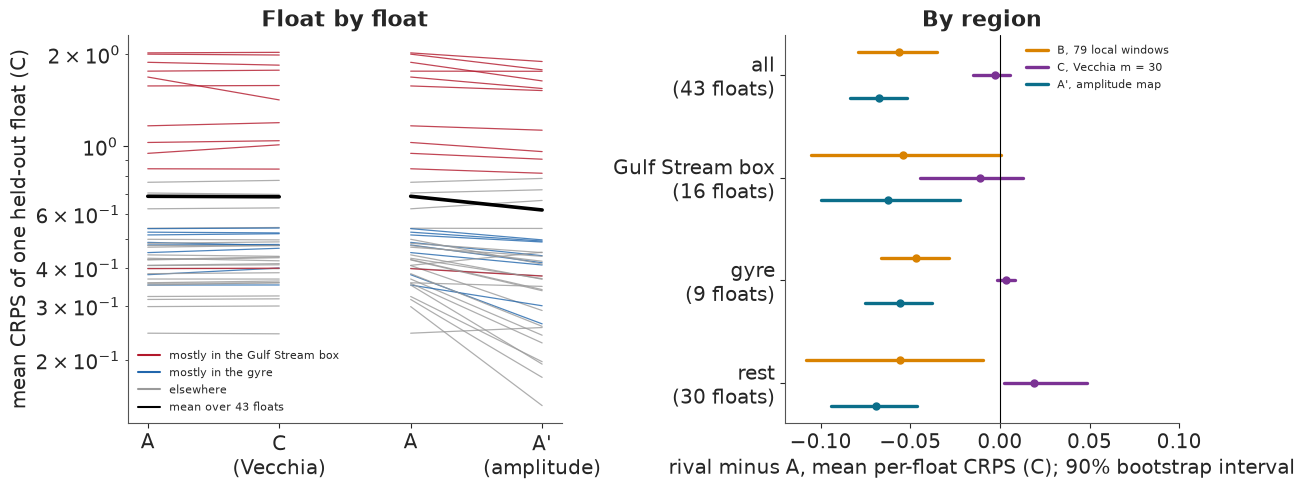

In [12]:
fig, (slope, intervals) = plt.subplots(1, 2, figsize=(12, 4.8), width_ratios=(1.1, 1))
fa = per_float(crps["A"])
float_region = {k: np.bincount(region_ho[float_ho == k], minlength=3).argmax() for k in fa}
for x0, m in ((0, "C"), (2, "Afix")):
    fm = per_float(crps[m])
    for k in fa:
        colour = ("#b2182b", "#2166ac", "#9a9a9a")[float_region[k]]
        slope.plot([x0, x0 + 1], [fa[k], fm[k]], color=colour, lw=0.9, alpha=0.8)
    slope.plot([x0, x0 + 1], [np.mean(list(fa.values())), np.mean(list(fm.values()))], color="black", lw=2.6)
slope.set_xticks([0, 1, 2, 3], ["A", "C\n(Vecchia)", "A", "A'\n(amplitude)"])
slope.set(yscale="log", ylabel="mean CRPS of one held-out float (C)", title="Float by float")
slope.legend(handles=[Line2D([], [], color=c_, label=l_) for c_, l_ in
                      (("#b2182b", "mostly in the Gulf Stream box"), ("#2166ac", "mostly in the gyre"),
                       ("#9a9a9a", "elsewhere"), ("black", "mean over 43 floats"))], fontsize=8, frameon=False)
wheres = ("all", "Gulf Stream box", "gyre", "rest")
for i, m in enumerate(("B", "C", "Afix")):
    for j, where in enumerate(wheres):
        d, lo_, hi_, nf = race[(m, where)]
        yy = j + (i - 1) * 0.22
        intervals.plot([lo_, hi_], [yy, yy], color=COLOR[m], lw=2.4)
        intervals.plot(d, yy, "o", color=COLOR[m], ms=5)
intervals.axvline(0, color="black", lw=0.8)
intervals.set_yticks(range(4), [f"{w}\n({race[('B', w)][3]} floats)" for w in wheres])
intervals.invert_yaxis()
intervals.set(xlabel="rival minus A, mean per-float CRPS (C); 90% bootstrap interval", title="By region")
intervals.set_xlim(-0.12, 0.1)
intervals.legend(handles=[Line2D([], [], color=COLOR[m], lw=2.4, label=LABEL[m]) for m in ("B", "C", "Afix")],
                 fontsize=8, frameon=False, loc="upper right");

On the left, the lines from A to C are nearly flat for every float: Vecchia and the exact fit make the same
predictions. From A to A' most lines fall. The steepest falls are floats in the quiet parts of the basin,
where A's intervals were far too wide and CRPS charges for the width; the Gulf Stream floats, the top of the
chart, fall less, and some barely move. On the right, the gyre has only 9 floats. Outside both boxes
Vecchia is a little worse than the exact fit, by 0.02 C with an interval just clear of zero; we did not plan
this comparison, so we only note it.

Hence the title: exactness was not worth its price here. It bought a likelihood we could optimise exactly
and check against NUTS, and a Hessian, but not a better map. The better map came from a different idea, letting the
variance vary, which B achieved with small exact fits and A' by putting B's amplitudes back into an exact fit.

## 7 · Is the uncertainty right?

A nominal 90% interval should contain the held-out value 90% of the time. A whole-basin coverage figure is
the number most reports would print. Here it is, region by region.

In [13]:
cover = pd.DataFrame({LABEL[m]: [pack[f"ho_{m}_cover"].mean()] + [pack[f"ho_{m}_cover"][region_ho == r].mean() for r in range(3)]
                      for m in ("A", "B", "C", "Afix", "Afixt")}, index=["all"] + list(REGIONS)).T
print(f"Held-out profiles: all {len(y_ho):,}; " + ", ".join(f"{REGIONS[r]} {(region_ho == r).sum()}" for r in range(3)))
print("Coverage of nominal 90% intervals (%):")
print((100 * cover).round(1).to_string())
z_A = (y_ho - pack["ho_A_mean"]) / np.sqrt(pack["ho_A_latent_var"] + np.exp(2 * fits["fit_A_f64"]["theta"][8]))
z_F = (y_ho - pack["ho_Afix_mean"]) / np.sqrt(pack["ho_Afix_latent_var"] + np.exp(2 * fits["fit_Afix_f64"]["theta"][8]))
print(f"\nShare of held-out profiles beyond 3 predictive sd: A {np.mean(np.abs(z_A) > 3):.1%}, "
      f"A' {np.mean(np.abs(z_F) > 3):.1%} (a Gaussian gives 0.3%)")

Held-out profiles: all 2,116; Gulf Stream box 592, gyre 295, rest 1229
Coverage of nominal 90% intervals (%):
                      all  Gulf Stream box  gyre  rest
A, exact stationary  90.4             67.7  99.7  99.0
B, 79 local windows  89.8             84.1  88.8  92.8
C, Vecchia m = 30    90.5             68.4  99.7  99.0
A', amplitude map    90.5             80.9  90.8  95.0
A'-t                 90.7             81.1  91.5  95.1

Share of held-out profiles beyond 3 predictive sd: A 4.0%, A' 1.6% (a Gaussian gives 0.3%)


**Failure 1: exact but wrong where it matters.** Over the whole basin A's 90% intervals cover 90.4% of the
held-out profiles, which looks perfect. Region by region, they cover 67.7% in the Gulf Stream box and 99.7% in
the gyre. The single number averages a model far too sure of itself where the ocean is violent and far too
unsure where it is calm, weighted by where the held-out floats happened to be. The most expensive computation
in the notebook produced uncertainty that is wrong where it matters, and a check at the wrong level would
have passed it. Vecchia, with the same kernel, fails the same way.

**The fix, and how far it got.** Kuusela & Stein's answer is to let the covariance vary. B does that window
by window; A' keeps one exact fit and multiplies the kernel by an amplitude $D(\text{place})$, a 500 km
Gaussian-weighted average of the log signal sd of B's windows. A' raises coverage in the box from 67.7% to
80.9% and brings the gyre down to 90.8%. We had hoped for 85% in the box, and A' misses it,
as does B (84.1%). The tails are still too heavy: 1.6% of held-out profiles fall beyond three predictive sd
under A', against 0.3% for a Gaussian, so the Student-t nugget was fitted to A' as well. It changed nothing
(A'-t covers 81.1%), for the reason it changed nothing for A: a heavier-tailed noise term cannot help when
the noise term has no weight. What would help is heavy tails in the field itself, a front that moves, which
this model does not have.

The maps make the same point at the scale of 5-degree cells, centred on the nominal 90%: red is
overconfident, blue underconfident.

Amplitude multiplier D over the ocean cells: 0.52 to 2.46; in the Gulf Stream box median 1.80, in the gyre 0.80


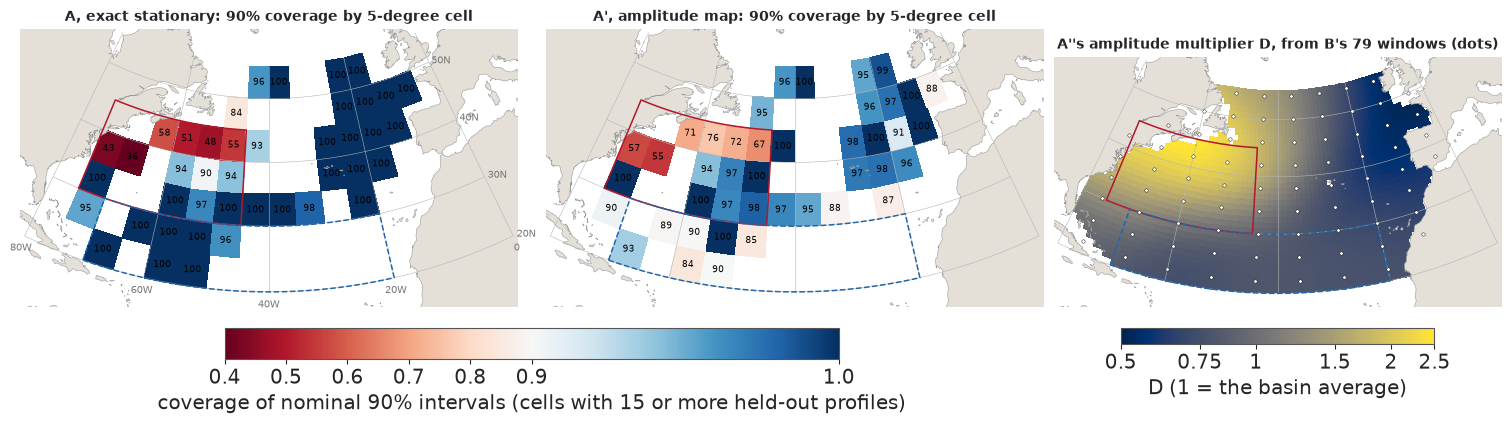

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), width_ratios=(1, 1, 0.9))
lat5, lon5 = (np.floor(pack["ho_lat"] / 5) * 5 + 2.5), (np.floor(pack["ho_lon"] / 5) * 5 + 2.5)
cells = pd.DataFrame({"lat": lat5, "lon": lon5, "A": pack["ho_A_cover"], "Afix": pack["ho_Afix_cover"]})
cell_cov = cells.groupby(["lat", "lon"]).agg(n=("A", "size"), A=("A", "mean"), Afix=("Afix", "mean")).reset_index()
cell_cov = cell_cov[cell_cov["n"] >= 15]
norm = TwoSlopeNorm(vcenter=0.9, vmin=0.4, vmax=1.0)
for ax, m in zip(axes[:2], ("A", "Afix")):
    X, Y, field = gridded(cell_cov["lat"], cell_cov["lon"], cell_cov[m], 5.0)
    image = ax.pcolormesh(X, Y, field, cmap="RdBu", norm=norm, shading="flat", zorder=1)
    for _, row in cell_cov.iterrows():
        ax.text(*lcc(row["lat"], row["lon"]), f"{row[m]:.0%}".replace("%", ""), fontsize=6.5, ha="center",
                va="center", zorder=6, color="black")
    basemap(ax, labels=ax is axes[0])
    ax.set_title(f"{LABEL[m]}: 90% coverage by 5-degree cell", fontsize=10)
fig.colorbar(image, ax=axes[:2], shrink=0.6, orientation="horizontal", label="coverage of nominal 90% intervals "
             "(cells with 15 or more held-out profiles)")
amp_lat, amp_lon = np.meshgrid(np.arange(20.5, 55, 1.0), np.arange(-79.5, 0, 1.0), indexing="ij")
ocean_cells = np.isin(amp_lat.ravel() * 1000 + amp_lon.ravel(), cell_lat * 1000 + cell_lon)
la_, lo_ = amp_lat.ravel()[ocean_cells], amp_lon.ravel()[ocean_cells]
centres, log_sd = np.asarray(amp["centres"]), np.asarray(amp["log_sd"])
p1, p2 = np.radians(la_)[:, None], np.radians(centres[None, :, 0])
hav = (np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(centres[None, :, 1] - lo_[:, None]) / 2) ** 2)
dist = 2 * R_EARTH * np.arcsin(np.sqrt(np.clip(hav, 0, 1)))
w = np.exp(-0.5 * (dist / amp["bandwidth_km"]) ** 2)
D = np.exp((w * log_sd).sum(1) / w.sum(1) - amp["norm"])
X, Y, field = gridded(la_, lo_, D, 1.0)
image = axes[2].pcolormesh(X, Y, field, cmap="cividis", norm=LogNorm(0.5, 2.5), shading="flat", zorder=1)
axes[2].scatter(*lcc(centres[:, 0], centres[:, 1]), s=6, color="white", edgecolor="black", lw=0.3, zorder=7)
basemap(axes[2], labels=False)
axes[2].set_title("A''s amplitude multiplier D, from B's 79 windows (dots)", fontsize=10)
bar = fig.colorbar(image, ax=axes[2], shrink=0.7, orientation="horizontal", label="D (1 = the basin average)")
bar.set_ticks([0.5, 0.75, 1, 1.5, 2, 2.5], labels=["0.5", "0.75", "1", "1.5", "2", "2.5"])
bar.minorticks_off()
print(f"Amplitude multiplier D over the ocean cells: {D.min():.2f} to {D.max():.2f}; in the Gulf Stream box median "
      f"{np.median(D[in_box(la_, lo_, GULF)]):.2f}, in the gyre {np.median(D[in_box(la_, lo_, GYRE)]):.2f}");

Under A the cells along the Gulf Stream are deep red, covering 36-58% where they promise 90%, while almost
every cell of the gyre and the eastern basin is dark blue, covering everything. A' lifts the red cells to
55-76% and brings most blue ones down towards 90%, but the stream is still overconfident, worst in the two
cells nearest the American coast. The amplitude map on the right shows how it helps: the windows find the
signal sd 1.8 times the basin average in the box (up to 2.5 times towards the Grand Banks), 0.8 times in the
gyre and about half in the eastern basin, and A' carries that into the exact fit. What it cannot carry is the
shape of the variability at a front: a stream that meanders produces jumps of 10 C that a Gaussian with any
smooth variance calls nearly impossible.

## 8 · Can float32 be trusted?

The price chart made float32 on the GPU look like the only sensible choice. But a float32 Cholesky factor can
carry a relative error up to about $n\,\kappa(K)\,\epsilon$, with $\epsilon = 1.2 \times 10^{-7}$ and $\kappa(K)$
the condition number, the ratio of the largest eigenvalue to the smallest (Higham 2002). The smallest
eigenvalue is about the nugget variance, so a smooth kernel with a tiny nugget is the dangerous case. Along the
optimiser's path for our Matern 1/2 model, the float32 log density was within 0.03-0.12 nats of float64 at n =
5,000-20,000, but its gradient carried absolute errors of 0.1-0.5, which a finite-difference Hessian with a
step of $10^{-4}$ turns into nonsense; hence the float64 stages of part 4. The stored run also built a
deliberately smooth model, an ExpQuad kernel with scales of 1,500 km, 1,000 km and 200 days, at
signal-to-nugget variance ratios of $10^3$ to $10^5$, and factored it on the GPU in both precisions. We repeat
a small version here on the CPU, with the kernel built in float32 arithmetic as the GPU did.

In [15]:
live = []
sub_order = np.random.default_rng(0).permutation(len(train))
X_train = mercator(train["lat"], train["lon"], train["t_days"])
for n in (1000, 2000, 3000):
    Xs = X_train[np.sort(sub_order[:n])]
    signal_eig = None
    for ratio in (1e2, 1e3, 1e4, 1e5):
        theta_eq = np.array([-20.0, 0, 0, 0, 0.0, np.log(1500), np.log(1000), np.log(200), 0.5 * np.log(1 / ratio), 0.0])
        K64 = full_cov(Xs, theta_eq, nu="inf")
        logdet64 = 2 * np.log(np.diag(np.linalg.cholesky(K64))).sum()
        if signal_eig is None:  # the nugget only shifts every eigenvalue, so one decomposition per n will do
            signal_eig = np.linalg.eigvalsh(K64) - np.exp(2 * theta_eq[8])
        eig = signal_eig + np.exp(2 * theta_eq[8])
        K32 = full_cov(Xs, theta_eq, nu="inf", dtype=np.float32)
        try:
            diag32 = np.diag(np.linalg.cholesky(K32)).astype(np.float64)
            err = 2 * np.log(diag32).sum() - logdet64 if np.all(np.isfinite(diag32)) else np.nan
        except np.linalg.LinAlgError:
            err = np.nan
        live.append({"n": n, "ratio": ratio, "condition": eig[-1] / eig[0], "logdet error (nats)": err})
live = pd.DataFrame(live)
print("Here, CPU (LAPACK), ExpQuad, kernel built in float32:")
print(live.to_string(index=False, na_rep="failed", formatters={"condition": "{:.1e}".format, "ratio": "{:.0e}".format,
                                                               "logdet error (nats)": "{:+.3f}".format}))
gpu_rows = pd.DataFrame(scores["failure_runs"]["expquad"])
print("\nStored run, GPU, ExpQuad, kernel built in float32 (condition estimated as largest eigenvalue x ratio):")
print(gpu_rows[["n", "ratio", "cond_est", "f32_finite", "logdet_err"]].to_string(
    index=False, na_rep="failed", formatters={"cond_est": "{:.1e}".format, "ratio": "{:.0e}".format,
                                              "logdet_err": "{:+.1f}".format}))

Here, CPU (LAPACK), ExpQuad, kernel built in float32:
   n ratio condition logdet error (nats)
1000 1e+02   2.2e+05              +0.006
1000 1e+03   2.2e+06              -0.044
1000 1e+04   2.2e+07              -0.305
1000 1e+05   2.2e+08              -9.148
2000 1e+02   4.5e+05              +0.012
2000 1e+03   4.5e+06              -0.120
2000 1e+04   4.5e+07              -1.408
2000 1e+05   4.5e+08             -93.102
3000 1e+02   6.8e+05              +0.019
3000 1e+03   6.8e+06              -0.202
3000 1e+04   6.8e+07              -3.310
3000 1e+05   6.8e+08              failed

Stored run, GPU, ExpQuad, kernel built in float32 (condition estimated as largest eigenvalue x ratio):
    n ratio cond_est  f32_finite logdet_err
 5000 1e+03  1.2e+07        True      -64.6
 5000 1e+04  1.2e+08       False     failed
 5000 1e+05  1.2e+09       False     failed
10000 1e+03  2.3e+07        True     -221.4
10000 1e+04  2.3e+08       False     failed
10000 1e+05  2.3e+09       False     failed
2

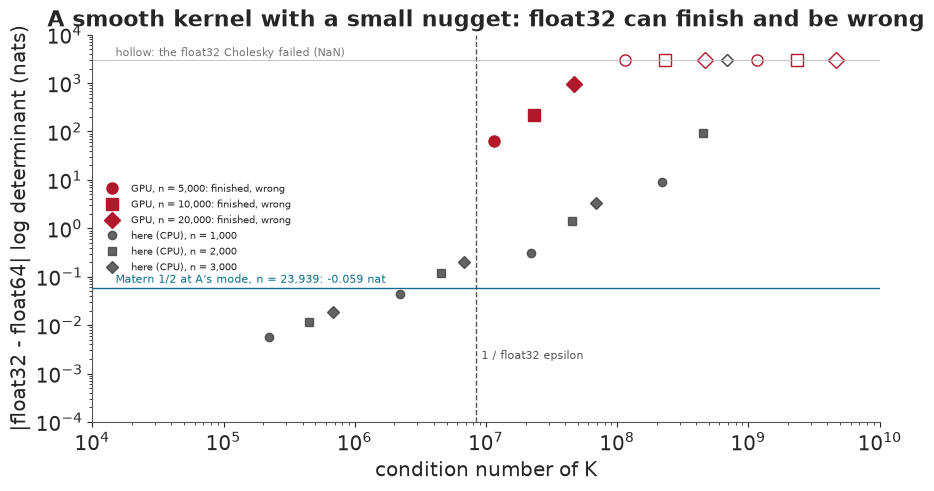

In [16]:
fig, ax = plt.subplots(figsize=(9, 4.8))
eps32 = scores["failure_runs"]["eps32"]
for n, marker in ((5000, "o"), (10000, "s"), (20000, "D")):
    rows_n = gpu_rows[gpu_rows["n"] == n]
    ok = rows_n["f32_finite"]
    ax.plot(rows_n.loc[ok, "cond_est"], rows_n.loc[ok, "logdet_err"].abs(), marker, color="#b2182b", ms=8,
            label=f"GPU, n = {n:,}: finished, wrong")
    ax.plot(rows_n.loc[~ok, "cond_est"], np.full((~ok).sum(), 3e3), marker, mfc="white", color="#b2182b", ms=8)
for n, marker in ((1000, "o"), (2000, "s"), (3000, "D")):
    rows_n = live[(live["n"] == n)]
    ok = rows_n["logdet error (nats)"].notna()
    ax.plot(rows_n.loc[ok, "condition"], rows_n.loc[ok, "logdet error (nats)"].abs(), marker, color="#3d3d3d", ms=6,
            alpha=0.8, label=f"here (CPU), n = {n:,}")
    ax.plot(rows_n.loc[~ok, "condition"], np.full((~ok).sum(), 3e3), marker, mfc="white", color="#3d3d3d", ms=6)
ax.axvline(1 / eps32, color="#555555", ls="--", lw=1)
ax.text(1.1 / eps32, 2e-3, "1 / float32 epsilon", fontsize=8, color="#555555")
ax.axhline(abs(scores["failure_runs"]["matern_full"]["err"]), color="#0b6e8a", lw=1)
ax.text(1.5e4, 0.075, f"Matern 1/2 at A's mode, n = {N_FULL:,}: {scores['failure_runs']['matern_full']['err']:+.3f} nat",
        fontsize=8, color="#0b6e8a")
ax.axhline(3e3, color="#bbbbbb", lw=0.6)
ax.text(1.5e4, 3.6e3, "hollow: the float32 Cholesky failed (NaN)", fontsize=8, color="#777777")
ax.set(xscale="log", yscale="log", xlim=(1e4, 1e10), ylim=(1e-4, 1e4), xlabel="condition number of K",
       ylabel="|float32 - float64| log determinant (nats)",
       title="A smooth kernel with a small nugget: float32 can finish and be wrong")
ax.legend(fontsize=7.5, frameon=False, loc="center left");

**Failure 2: float32 can be silently wrong.** On the GPU, at a signal-to-nugget ratio of $10^3$, the float32
factor finished without complaint and its log determinant was wrong by 65, 221 and 948 nats at n = 5,000,
10,000 and 20,000. Nothing raised an error and nothing was NaN; an optimiser would have followed it
anywhere. At ratios of $10^4$ and above it failed outright, which is the safer outcome. On the CPU's LAPACK
at smaller n the pattern is the same with the numbers moved: the error grows with n and the condition
number, passes a nat at a few times $10^7$, and when this notebook was built reached 9 and 93 nats at a ratio
of $10^5$ with n = 1,000 and 2,000, again with no error raised (another machine's LAPACK will differ
somewhat). For the Matern 1/2 model actually fitted, the error at full size was 0.06 nats: a rough kernel
has no near-zero eigenvalues to lose. Precision is a property of the model as much as of the hardware. The
general rules: a kernel with some roughness and a nugget, the log determinant summed in float64 whatever the
factor's precision, and every decision that rests on small differences (the Hessian, the end of the
optimisation, the importance weights) in float64. Iterative refinement, often suggested, improves $K^{-1}y$
and does nothing for the log determinant.

## 9 · Where should the 20 floats go?

**The objective.** With the hyperparameters fixed, a Gaussian process's posterior covariance after new
observations at points $P$ is

$$\Sigma_{T\mid P} = \Sigma_T - \Sigma_{TP}(\Sigma_P + s_n^2 I)^{-1}\Sigma_{PT},$$

for any target points $T$, and it does not depend on the values observed. The targets are 512 two-degree
ocean cells at four days spread through 2025, 2,048 points in all. "Before" is their mean posterior variance
given the 2023-2024 training data and the 13,295 profiles the real 2025 network reported (excluding held-out
floats). A candidate float is a block of up to 36 observations along a drift track, and adding it removes
$\operatorname{tr}\, \Sigma_{TB}(\Sigma_B + s_n^2 I)^{-1}\Sigma_{BT} / |T|$ from the mean target variance.
The greedy rule picks the best block among 200 candidate launch sites (a Halton sequence over the open
ocean), updates $\Sigma$, and repeats 20 times, the standard method for sensor placement (Krause, Singh &
Guestrin 2008). Candidate sites ignore ship routes; a real programme launches where ships go.

Two baselines use the same sites and drift: **gap-filling**, which picks the site farthest from every 2025
profile and from the sites already chosen, and 50 random sets of 20. Each rule runs on the same four drift
replicates, for 11 hyperparameter draws under A (the mode and ten Sobol points) and at the mode under A'
and A'-t.

In [17]:
dm = scores["design_models"]
design_table = pd.DataFrame({
    m: {"mean target variance before (C^2)": dm[m]["before"], "removed by greedy 20": dm[m]["greedy_removed"],
        "share removed": dm[m]["share_removed_greedy"], "removed by gap-filling 20": dm[m]["gap_removed"],
        "removed by random 20 (mean of 50)": dm[m]["random_removed"], "greedy / gap-filling": dm[m]["greedy_over_gap"],
        "greedy / random": dm[m]["greedy_over_random"], "runs (draws x replicates)": dm[m]["chunks"]}
    for m in ("A", "Afix", "Afixt")}).rename(columns={m: LABEL[m] for m in LABEL})
print(design_table.map(lambda v: f"{v:.4g}").to_string())

                                  A, exact stationary A', amplitude map     A'-t
mean target variance before (C^2)                1.76             1.216    1.215
removed by greedy 20                          0.03909           0.03691  0.03684
share removed                                 0.02222           0.03036  0.03032
removed by gap-filling 20                     0.02423           0.01871  0.01871
removed by random 20 (mean of 50)             0.01981           0.01243  0.01241
greedy / gap-filling                            1.614             1.973    1.969
greedy / random                                 1.973             2.968    2.969
runs (draws x replicates)                          44                 4        4


Twenty well-placed floats remove 2.2% of the mean target variance under A and 3.0% under A'. That is small,
and it should be: the 2025 network already reported 13,295 profiles, and at 100 km and a month each new
profile informs only a small patch of the 2,048 targets. Within that small number, greedy siting is clearly
better than the alternatives under both models: 1.6 and 2.0 times what gap-filling removes, 2.0 and 3.0
times random. A' has less variance to remove (1.22 against 1.76 C$^2$) because it is more certain in the
calm parts of the basin.

The figure shows the design under A at its mode for the first drift replicate, and the animation after it
shows it happening: first the 2025 field every other month with the network's profiles, then the variance
draining as each float is added.

Mean target variance under A at the mode, replicate 1: 1.760 -> 1.722 C^2; first pick removes 0.0031, the 20th 0.0015


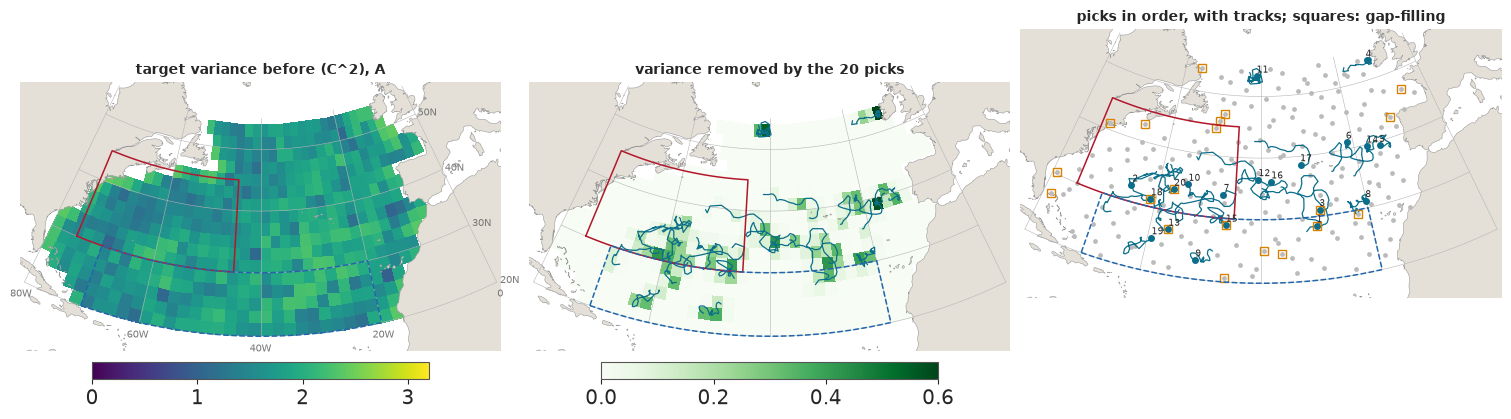

In [18]:
sites = pack["design_sites"].astype(float)
target_cells = pack["design_target_cells"].astype(float)
var_maps = pack["design_var_maps"].reshape(21, -1, 4).mean(axis=2)  # mean over the four target days
picks_A = pack["design_picks_mode"]
drift = {rep: (pack[f"drift_lat_{rep}"], pack[f"drift_lon_{rep}"], pack[f"drift_valid_{rep}"]) for rep in range(4)}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
X, Y, field = gridded(target_cells[:, 0], target_cells[:, 1], var_maps[0], 2.0)
im0 = axes[0].pcolormesh(X, Y, field, cmap="viridis", norm=plt.Normalize(0, 3.2), shading="flat")
X, Y, field = gridded(target_cells[:, 0], target_cells[:, 1], var_maps[0] - var_maps[-1], 2.0)
im1 = axes[1].pcolormesh(X, Y, field, cmap="Greens", norm=plt.Normalize(0, 0.6), shading="flat")
axes[2].scatter(*lcc(sites[:, 0], sites[:, 1]), s=6, color="#bbbbbb", zorder=4, label="200 candidate sites")
lat_d, lon_d, valid_d = drift[0]
for rank, s in enumerate(picks_A):
    for ax in axes[1:]:
        ax.plot(*lcc(lat_d[s][valid_d[s]], lon_d[s][valid_d[s]]), color="#0b6e8a", lw=0.9, zorder=5)
    axes[2].plot(*lcc(sites[s, 0], sites[s, 1]), "o", color="#0b6e8a", ms=4, zorder=6)
    axes[2].text(*lcc(sites[s, 0] + 0.6, sites[s, 1]), str(rank + 1), fontsize=6.5, zorder=7)
gap = pack["design_gap_picks"]
axes[2].plot(*lcc(sites[gap, 0], sites[gap, 1]), "s", mfc="none", color="#d98200", ms=6, zorder=6)
for ax, title in zip(axes, ("target variance before (C^2), A", "variance removed by the 20 picks",
                            "picks in order, with tracks; squares: gap-filling")):
    basemap(ax, labels=ax is axes[0])
    ax.set_title(title, fontsize=10)
fig.colorbar(im0, ax=axes[0], shrink=0.7, orientation="horizontal", pad=0.02)
fig.colorbar(im1, ax=axes[1], shrink=0.7, orientation="horizontal", pad=0.02)
print(f"Mean target variance under A at the mode, replicate 1: {pack['design_trace'][0]:.3f} -> {pack['design_trace'][-1]:.3f} "
      f"C^2; first pick removes {pack['design_trace'][0] - pack['design_trace'][1]:.4f}, the 20th "
      f"{pack['design_trace'][-2] - pack['design_trace'][-1]:.4f}");

In [19]:
map25 = store.load_json("replay")["map2025"]
c25_lat, c25_lon, days25 = (np.asarray(map25[k]) for k in ("cell_lat", "cell_lon", "days"))
net25 = y25[~y25["held"]]
month_names = pd.date_range("2025-01-01", periods=12, freq="MS").strftime("%B")
plt.rcParams["animation.embed_limit"] = 30
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")  # the style's layout engine
fig = plt.figure(figsize=(6.0, 3.85), dpi=66, layout="none")
ax = fig.add_axes([0.0, 0.08, 0.86, 0.84])
cax = fig.add_axes([0.87, 0.2, 0.025, 0.6])
MONTHS = (0, 2, 4, 6, 8, 10)  # every other month of 2025


def frame(k):
    ax.clear()
    cax.clear()
    if k < len(MONTHS):
        mo = MONTHS[k]
        X, Y, field = gridded(c25_lat, c25_lon, pack["map2025_mean"][mo], 2.0)
        image = ax.pcolormesh(X, Y, field, cmap="RdBu_r", norm=TwoSlopeNorm(0, -2.5, 2.5), shading="flat")
        now = net25[np.abs(net25["t_days"] - days25[mo]) < 15]
        ax.plot(*lcc(now["lat"], now["lon"]), ".", ms=2, color="black", zorder=5)
        title = f"2025 anomaly at 100 dbar, A: {month_names[mo]}, with {len(now):,} network profiles"
        label = "C"
    else:
        j = k - len(MONTHS)
        X, Y, field = gridded(target_cells[:, 0], target_cells[:, 1], var_maps[j], 2.0)
        image = ax.pcolormesh(X, Y, field, cmap="viridis", norm=plt.Normalize(0, 3.2), shading="flat")
        for s in picks_A[:j]:
            ax.plot(*lcc(lat_d[s][valid_d[s]], lon_d[s][valid_d[s]]), color="#ff3d7f", lw=1.2, zorder=5)
            ax.plot(*lcc(sites[s, 0], sites[s, 1]), "o", color="#ff3d7f", ms=3.5, zorder=6)
        title = f"Target variance after {j} of 20 floats: mean {pack['design_trace'][j]:.3f} C$^2$"
        label = "C$^2$"
    basemap(ax, labels=False)
    ax.set_title(title, fontsize=9)
    fig.colorbar(image, cax=cax, label=label)


animation = FuncAnimation(fig, frame, frames=len(MONTHS) + 21, interval=450)
html = animation.to_jshtml(default_mode="once")
plt.close(fig)
print(f"Animation: {len(MONTHS) + 21} frames, {len(html) / 1e6:.1f} MB")
HTML(html)

Animation: 27 frames, 1.9 MB


The picks spread along a band from the Bahamas to the Canaries, 28-40N, with a few in the north-east, in open
water. Each float carves out a narrow corridor of lower variance along its track, and the gains shrink from
0.0031 C$^2$ for the first to 0.0015 for the twentieth, as later floats start to share their neighbourhoods.
Under A the variance map is geometry, so these are holes in the network, weighted by how long a float would
stay in them and inside the target box. Gap-filling (squares) finds holes too, but its holes are mostly at
the edges: off Nova Scotia and Labrador, against Iberia and Africa, along the southern boundary at 20N. They
are the points farthest from any profile because nothing is beyond them, and a float launched there may
spend part of its year aground or outside the box, where the design stops counting it. Measured on the four
drift replicates, a gap-filling track counts for 71-79% of its year, a greedy one for 89-96%, and the
average candidate for 86%: much of the factor of 1.6 is time lost at the edges.

Worse, some of those edges are not open ocean. The candidate sites excluded only land, and nothing checked
the depth of the water, so the gap rule went where Argo cannot work: inside Long Island Sound (204 km from
any profile of 2023-2025, which is exactly why it is a gap), on the Grand Banks, beside Browns Bank on the
Scotian Shelf, on the Little Bahama Bank and on the Labrador Shelf. These are judged from geography, not
from bathymetry. A float that profiles to 2,000 m cannot work on a shelf a hundred metres deep, and there
are no profiles there because floats cannot be there. We come back to this below, with a rerun.

### How stable is the list?

A coordinator would want a list that does not change when the model does. The stored run tested three kinds
of change: the hyperparameters (11 draws under A, each run on the same four drift replicates), the drift (the
four replicates), and the model (A against A'). The stipple maps below show how often each site was picked.

A: picked by all 11 draws within a replicate: the mean overlap of a draw's 20 picks with the mode's is 19.5; between replicates 4.3 of 20
A': between replicates 7.5 of 20. Sites picked in 4, 3, 2, 1 of the 4 replicates: 2, 6, 15, 24
A and A' share 3 of their 20 most-picked sites
Weighting the targets to the Gulf Stream box changes 14-19 of A's 20 picks; fixed stations instead of drifting floats change 13 of 20


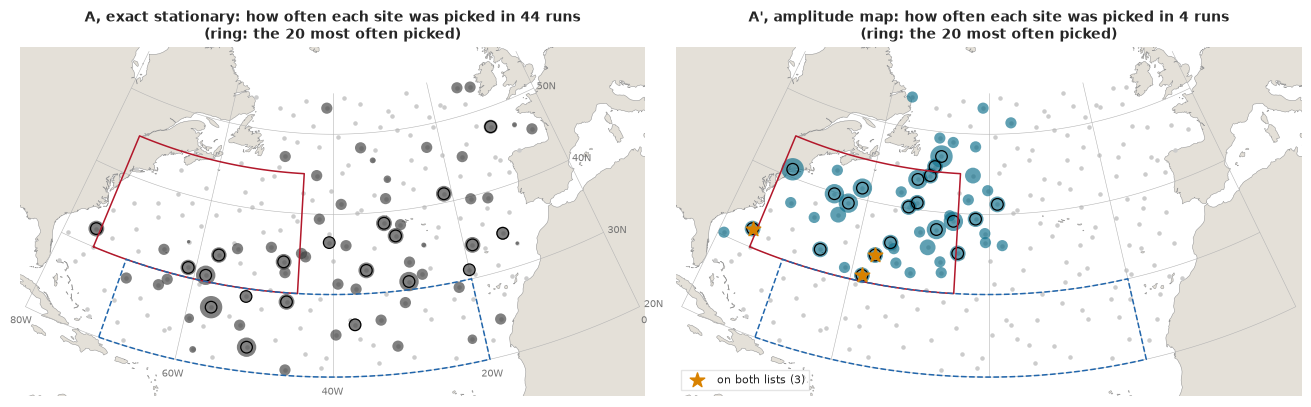

In [20]:
freq_A, freq_F = pack["design_freq_A"].astype(float), pack["design_freq_Afix"].astype(float)
rec = scores["design"]
rec_A = np.asarray(dm["A"]["recommended_20"])
rec_F = np.asarray(rec["recommended_index"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, freq, runs, top, m in ((axes[0], freq_A, 44, rec_A, "A"), (axes[1], freq_F, 4, rec_F, "Afix")):
    ax.scatter(*lcc(sites[:, 0], sites[:, 1]), s=5, color="#cccccc", zorder=4)
    chosen = freq > 0
    ax.scatter(*lcc(sites[chosen, 0], sites[chosen, 1]), s=260 * freq[chosen] / runs, color=COLOR[m], alpha=0.65,
               edgecolor="none", zorder=5)
    ax.scatter(*lcc(sites[top, 0], sites[top, 1]), s=70, facecolor="none", edgecolor="black", lw=0.9, zorder=6)
    basemap(ax, labels=ax is axes[0])
    ax.set_title(f"{LABEL[m]}: how often each site was picked in {runs} runs\n(ring: the 20 most often picked)", fontsize=10)
both = np.intersect1d(rec_A, rec_F)
axes[1].scatter(*lcc(sites[both, 0], sites[both, 1]), marker="*", s=120, color="#d98200", zorder=7,
                label=f"on both lists ({len(both)})")
axes[1].legend(fontsize=8, frameon=True, facecolor="white", loc="lower left")
counts_F = np.bincount(freq_F.astype(int))
print(f"A: picked by all 11 draws within a replicate: the mean overlap of a draw's 20 picks with the mode's is "
      f"{dm['A']['draw_overlap_with_mode_mean']:.1f}; between replicates {dm['A']['replicate_overlap_mean']:.1f} of 20")
print(f"A': between replicates {dm['Afix']['replicate_overlap_mean']:.1f} of 20. Sites picked in 4, 3, 2, 1 of the 4 "
      f"replicates: {counts_F[4]}, {counts_F[3]}, {counts_F[2]}, {counts_F[1]}")
print(f"A and A' share {len(both)} of their 20 most-picked sites")
gulf_changed = scores["design_variants"]["gulf_weight_top20_changed"]
print(f"Weighting the targets to the Gulf Stream box changes {min(gulf_changed)}-{max(gulf_changed)} of A's 20 picks; "
      f"fixed stations instead of drifting floats change {scores['design_variants']['fixed_sites_top20_changed']} of 20")

The picks barely depend on the hyperparameters: a draw from A's approximate posterior shares 19.5 of its 20
sites with the mode's list on the same drift replicate, the narrow posterior of 23,939 points at work. They
depend a great deal on the drift: two replicates share 4.3 of 20 sites under A and 7.5 under A'. A launch
site is good if the track it starts is good, and nobody knows the track. And they depend on the model: **A
and A' share 3 of their 20 most-picked sites.** Under A the picks spread over the data-poor parts of the
basin; under A' they gather along the Gulf Stream and its extension, where A' says the ocean varies. A' is
the better model, but its list rests on four replicates: 12 of its 20 sites were picked in 2 of the 4, and
ties were broken by the sites' order, so the bottom of the list is arbitrary.

Weighting the targets to the Gulf Stream box instead of the whole basin changes 14-19 of the 20 picks: which
uncertainty matters is the programme's choice, not the model's.

**Failure 3: fixed sites answer the wrong question.** Ranked as stations that stay put, 13 of the 20 sites
change. A station's value is the variance it removes where it stands, and a float from the box is a median
630 km from there within a year.

We decided in advance to turn all this into advice with three questions. Does greedy beat
gap-filling by at least 10% under the best-scoring model? If not, fill the gaps. If so, do A and A' agree
on at least 10 of their 20 sites? If they do, target these sites. If not, do they agree on the **regions**
(three latitude bands, 20-32N, 32-44N, 44-55N, each split at 40W), by a total variation distance of their
shares below 0.25? If they do, target a region; if not, fill the gaps. We compute it here from the stored picks.

In [21]:
def region_shares(idx):
    band = np.digitize(sites[idx, 0], [32.0, 44.0])
    return np.bincount(band * 2 + (sites[idx, 1] >= -40).astype(int), minlength=6) / len(idx)


def advise(ratio, rec_A, rec_F):
    """The three questions: (advice, sites shared, regional total variation)."""
    overlap = len(set(rec_A) & set(rec_F))
    tv = 0.5 * np.abs(region_shares(rec_A) - region_shares(rec_F)).sum()
    return (2 if ratio < 1.10 else 1 if overlap >= 10 else 3 if tv < 0.25 else 2), overlap, tv


ADVICE = {1: "target these sites", 2: "fill the gaps", 3: "target a region"}
best_model = min(rec["crps_by_model"], key=rec["crps_by_model"].get)
ratio = dm[best_model]["greedy_over_gap"]
advice, overlap, tv = advise(ratio, rec_A, rec_F)
shares = pd.DataFrame({"A": region_shares(rec_A), "A'": region_shares(rec_F)},
                      index=[f"{b}, {h}" for b in ("20-32N", "32-44N", "44-55N") for h in ("west of 40W", "east of 40W")])
print(shares.round(2).to_string())
print(f"\nBest model by CRPS: {LABEL[best_model]}; greedy / gap-filling {ratio:.2f} (>= 1.10: go on); sites shared "
      f"{overlap} of 20 (< 10: go on); regional total variation {tv:.2f} (>= 0.25)")
print(f"Advice: {advice} ({ADVICE[advice]})")
assert advice == rec["recommendation"] == 2 and overlap == rec["overlap_A_Afix"] and np.isclose(tv, rec["region_tv"])

                        A    A'
20-32N, west of 40W  0.30  0.05
20-32N, east of 40W  0.15  0.00
32-44N, west of 40W  0.20  0.75
32-44N, east of 40W  0.30  0.05
44-55N, west of 40W  0.00  0.15
44-55N, east of 40W  0.05  0.00

Best model by CRPS: A', amplitude map; greedy / gap-filling 1.97 (>= 1.10: go on); sites shared 3 of 20 (< 10: go on); regional total variation 0.70 (>= 0.25)
Advice: 2 (fill the gaps)


On the first design the answer is **fill the gaps**, and it is worth being exact about why. Siting by
variance does better under each model on its own, removing 1.6-2 times what gap-filling removes; but the
targeted list belongs to one model. A and A' agree on 3 sites, and their picks by region differ by a total variation of 0.70: under A,
45% of the picks are south of 32N and 30% in the mid-latitudes east of 40W; under A', 75% are at 32-44N west
of 40W, the latitudes of the Gulf Stream. Either list is a bet on its model, and the two disagree on exactly
what a list depends on, where the ocean is most variable. Gap-filling needs no model. The stored run did not
score A's list under A' or the reverse, so how much a wrong-model list would lose is not known. And as run,
"fill the gaps" sent floats onto shelves: 7 of its 20 sites are in shallow water, and so are 4 of A''s 20
most-picked sites, Long Island Sound among them.

### The design again, on water a float can work in

This is a change we made after seeing the result, so the first design stays above, unchanged, and the rerun
sits beside it. The repository has no bathymetry, so we use Argo's own record as a stand-in for water deep
enough to work in: a point counts as operable if at least 10 profiles of 2015-2022 (the climatology's years,
never fitted or scored) lie within 75 km. We chose that radius and count after looking at the sites above;
at 150 km the Grand Banks still pass, with 22-38 profiles each. The mask applies to the launch sites and to
the drift, so a track ends where it leaves operable water. Everything else is the first design's: the same
200 sites, targets, tracks, seeds and hyperparameter draws, and the same three questions. The rerun took 26
minutes on the GPU.

Sites with fewer than 10 profiles of 2015-2022 within 75 km: 10 of 200
  44.43N 50.26W   0 profiles  on the first gap-filling, A' list
  40.98N 73.35W   0 profiles  on the first gap-filling, A' list
  53.73N 55.79W   0 profiles  on the first gap-filling
  53.06N 11.58W   0 profiles  
  45.63N 49.61W   0 profiles  on the first gap-filling, A' list
  28.36N 12.55W   5 profiles  
  45.36N 56.44W   0 profiles  
  46.95N 48.64W   0 profiles  on the first gap-filling, A' list
  42.70N 66.19W   0 profiles  on the first gap-filling
  26.77N 78.66W   0 profiles  on the first gap-filling

Share of the year a float's track counts (A at its mode, by drift replicate): first design greedy 89%-96%, gap-filling 71%-79%, all 200 sites 86%; rerun greedy 93%-97%, gap-filling 85%-90%

                         A, exact stationary          A', amplitude map         
                                       first    rerun             first    rerun
removed by greedy 20                 0.03909  0.03844         

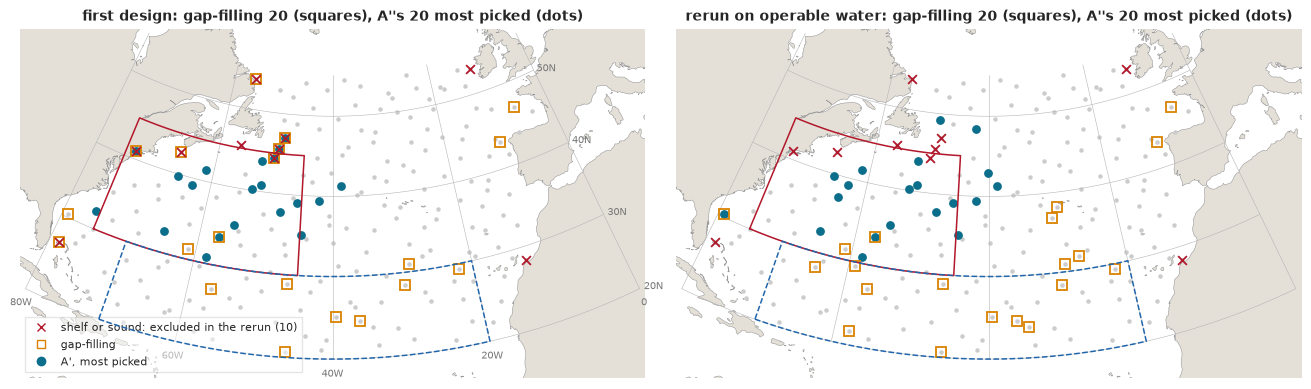

In [22]:
masked = store.load_json("design_masked_summary")
dmm = masked["models"]
allowed = pack["masked_allowed"].astype(bool)
excluded = np.flatnonzero(~allowed)
gap_m = pack["masked_design_gap_picks"]
counts75 = np.asarray(store.load_json("design_masked_inputs")["site_base_counts"])
print(f"Sites with fewer than {masked['operable_min']} profiles of 2015-2022 within {masked['operable_km']:.0f} km: "
      f"{len(excluded)} of {len(sites)}")
for j in excluded:
    on = [name for name, idx in (("gap-filling", gap), ("A' list", rec_F), ("A list", rec_A)) if j in idx]
    print(f"  {sites[j, 0]:5.2f}N {-sites[j, 1]:5.2f}W  {counts75[j]:2d} profiles  {'on the first ' + ', '.join(on) if on else ''}")
track_share = {"first": {"greedy": [], "gap": []}, "rerun": {"greedy": [], "gap": []}}
for rep in range(4):
    for run, valid, picks, gp in (("first", pack[f"drift_valid_{rep}"], pack[f"design_picks_rep{rep}"], gap),
                                  ("rerun", pack[f"masked_valid_{rep}"], pack[f"masked_picks_rep{rep}"], gap_m)):
        track_share[run]["greedy"].append(valid[picks].mean())
        track_share[run]["gap"].append(valid[gp].mean())
print(f"\nShare of the year a float's track counts (A at its mode, by drift replicate): first design greedy "
      f"{min(track_share['first']['greedy']):.0%}-{max(track_share['first']['greedy']):.0%}, gap-filling "
      f"{min(track_share['first']['gap']):.0%}-{max(track_share['first']['gap']):.0%}, all 200 sites "
      f"{np.mean([pack[f'drift_valid_{r}'].mean() for r in range(4)]):.0%}; rerun greedy "
      f"{min(track_share['rerun']['greedy']):.0%}-{max(track_share['rerun']['greedy']):.0%}, gap-filling "
      f"{min(track_share['rerun']['gap']):.0%}-{max(track_share['rerun']['gap']):.0%}")
side = pd.DataFrame({(LABEL[m], run): {"removed by greedy 20": d["greedy_removed"], "by gap-filling 20": d["gap_removed"],
                                       "by random 20": d["random_removed"], "greedy / gap-filling": d["greedy_over_gap"],
                                       "greedy / random": d["greedy_over_random"],
                                       "replicates share (of 20)": d["replicate_overlap_mean"]}
                     for m in ("A", "Afix") for run, d in (("first", dm[m]), ("rerun", dmm[m]))})
print("\n" + side.map(lambda v: f"{v:.4g}").to_string())
rec_A_m, rec_F_m = np.asarray(dmm["A"]["recommended_20"]), np.asarray(masked["decision"]["recommended_index"])
best_m = masked["decision"]["decision_model"]
advice_m, overlap_m, tv_m = advise(dmm[best_m]["greedy_over_gap"], rec_A_m, rec_F_m)
print(f"\nRerun, the same three questions: greedy / gap-filling under {LABEL[best_m]} {dmm[best_m]['greedy_over_gap']:.2f}; "
      f"sites shared by A and A' {overlap_m} of 20; regional total variation {tv_m:.2f}. Advice: {advice_m} ({ADVICE[advice_m]})")
print(f"First and rerun lists share {len(set(rec_A) & set(rec_A_m))} of 20 under A and {len(set(rec_F) & set(rec_F_m))} under A'")
assert advice_m == masked["decision"]["recommendation"] and overlap_m == masked["decision"]["overlap_A_Afix"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, gp, recF_, title in ((axes[0], gap, rec_F, "first design"), (axes[1], gap_m, rec_F_m, "rerun on operable water")):
    ax.scatter(*lcc(sites[:, 0], sites[:, 1]), s=5, color="#cccccc", zorder=4)
    ax.plot(*lcc(sites[gp, 0], sites[gp, 1]), "s", mfc="none", color="#d98200", ms=7, mew=1.3, zorder=6)
    ax.scatter(*lcc(sites[recF_, 0], sites[recF_, 1]), s=28, color=COLOR["Afix"], zorder=5)
    ax.scatter(*lcc(sites[excluded, 0], sites[excluded, 1]), marker="x", s=40, color="#b2182b", lw=1.3, zorder=7)
    basemap(ax, labels=ax is axes[0])
    ax.set_title(f"{title}: gap-filling 20 (squares), A''s 20 most picked (dots)", fontsize=10)
axes[0].legend(handles=[Line2D([], [], marker="x", ls="", color="#b2182b", label=f"shelf or sound: excluded in the rerun ({len(excluded)})"),
                        Line2D([], [], marker="s", ls="", mfc="none", color="#d98200", label="gap-filling"),
                        Line2D([], [], marker="o", ls="", color=COLOR["Afix"], label="A', most picked")],
               fontsize=8, frameon=True, facecolor="white", loc="lower left");

The mask removes 10 of the 200 sites, and they are the ones geography predicts: Long Island Sound, three
on or beside the Grand Banks, the Labrador Shelf, Browns Bank, the Little Bahama Bank, the St Pierre Bank
area south of Newfoundland, one west of Ireland and one between the Canaries and Africa. It is a stand-in,
not a depth chart: a site such as 30.4N 79.2W, over the Blake Plateau where floats pass in the Gulf Stream,
keeps its 31 profiles and stays in, though the water there is probably shallower than 2,000 m. Seven of the
first gap-filling sites were on the excluded list, and on operable water a gap-filling track now counts for
85-90% of its year, close to the greedy picks' 93-97%.

The targeted lists hardly move: 17 of A's 20 most-picked sites and 15 of A''s are the same as before. What
moves is the baseline, and it moves in opposite directions under the two models. Under A, gap-filling now
removes more than before (0.028 against 0.024 C$^2$), and greedy siting beats it by 1.4 times instead of
1.6. Under A', gap-filling removes less (0.012 against 0.019), no more than 20 random sites, and greedy beats
it by 2.7 times. The open-ocean gaps lie mostly in the subtropical gyre, 15 of the 20 south of 32N, and A
says the gaps are where the uncertainty is, while A' says the gyre is calm. The shelf sites had flattered
gap-filling under A', probably because they sit next to the Gulf Stream and the Labrador Current, where A'
expects large anomalies.

The three questions give the same answer, **fill the gaps**, and now for a plainer reason: greedy beats
gap-filling easily under the best model, A and A' share only 2 of their 20 sites, and their regions differ
by a total variation of 0.75, so neither a list nor a region survives a change of model, and the rule falls
back on gap-filling. But the rerun shows how weak that fallback is. On operable water gap-filling captures
about three quarters of the best targeted gain under A and three eighths under A', where a random spread of
20 open-ocean sites does as well.

## 10 · Does the objective predict anything?

Everything above trusts the posterior variance to say how much a float would help. That can be tested, a
little, on what really happened. In 2025, 73 new floats (outside the held-out set) were launched in the box
and reported 2,261 profiles. The stored run mapped 2025 at A's mode twice, with and without those floats,
and asked at the 993 profiles of 38 held-out floats in 2025: did the predicted variance reduction match the
realised reduction in squared error? With fixed hyperparameters the predicted reduction is exactly the
objective of part 9.

993 profiles of 38 held-out floats: predicted reduction 0.029 C^2, realised 0.230 C^2 (90% float bootstrap -0.01 to 0.49); realised minus predicted -0.04 to 0.47
  float 5907190 at 45N 57W, 71 profiles: predicted 0.0002, realised 1.64 C^2, 51% of the total realised reduction
  float 4902481 at 38N 68W, 34 profiles: predicted 0.0289, realised 3.23 C^2, 48% of the total realised reduction
The other 36 floats: predicted 0.032, realised 0.002 C^2; 17 got worse, 19 better
Rank correlation of predicted and realised over floats: 0.11


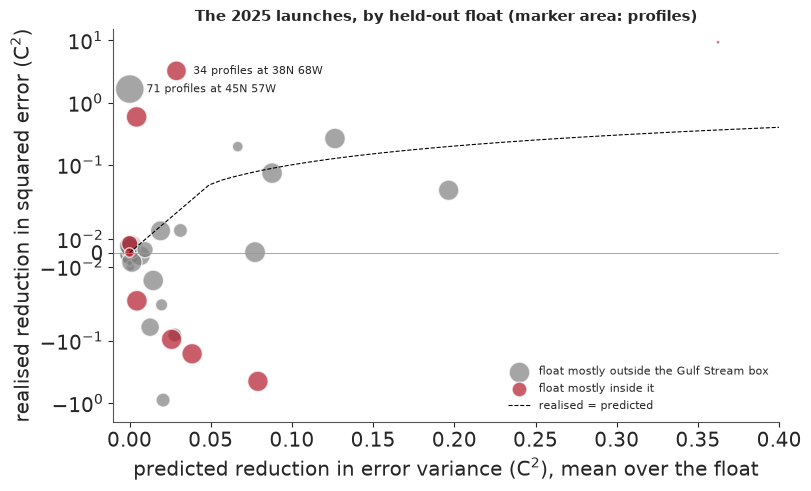

In [23]:
ne_y, ne_float = np.asarray(nat_exp["y"]), np.asarray(nat_exp["float_id"])
pred_p = np.asarray(nat_exp["var_h_without"]) - np.asarray(nat_exp["var_h_with"])
real_p = (ne_y - np.asarray(nat_exp["mean_h_without"])) ** 2 - (ne_y - np.asarray(nat_exp["mean_h_with"])) ** 2
ids = np.unique(ne_float)
pf = np.array([pred_p[ne_float == k].mean() for k in ids])
rf = np.array([real_p[ne_float == k].mean() for k in ids])
nf = np.array([(ne_float == k).sum() for k in ids])
boot = np.random.default_rng(92).integers(0, len(ids), (4000, len(ids)))
weights = nf[boot]
diff_b = ((rf - pf)[boot] * weights).sum(1) / weights.sum(1)
real_b = (rf[boot] * weights).sum(1) / weights.sum(1)
lo_d, hi_d = np.quantile(diff_b, [0.05, 0.95])
lo_r, hi_r = np.quantile(real_b, [0.05, 0.95])
print(f"{len(ne_y)} profiles of {len(ids)} held-out floats: predicted reduction {pred_p.mean():.3f} C^2, realised "
      f"{real_p.mean():.3f} C^2 (90% float bootstrap {lo_r:.2f} to {hi_r:.2f}); realised minus predicted "
      f"{lo_d:.2f} to {hi_d:.2f}")
share = rf * nf / (rf * nf).sum()
top2 = np.argsort(-share)[:2]
lat_f = np.array([np.mean(np.asarray(nat_exp["lat"])[ne_float == k]) for k in ids])
lon_f = np.array([np.mean(np.asarray(nat_exp["lon"])[ne_float == k]) for k in ids])
for k in top2:
    print(f"  float {ids[k]} at {lat_f[k]:.0f}N {-lon_f[k]:.0f}W, {nf[k]} profiles: predicted {pf[k]:.4f}, realised "
          f"{rf[k]:.2f} C^2, {share[k]:.0%} of the total realised reduction")
rest_ = np.setdiff1d(np.arange(len(ids)), top2)
print(f"The other {len(rest_)} floats: predicted {np.average(pf[rest_], weights=nf[rest_]):.3f}, realised "
      f"{np.average(rf[rest_], weights=nf[rest_]):.3f} C^2; {(rf[rest_] < 0).sum()} got worse, {(rf[rest_] > 0).sum()} better")
print(f"Rank correlation of predicted and realised over floats: {stats.spearmanr(pf, rf)[0]:.2f}")
assert np.isclose(pred_p.mean(), scores["natural_experiment"]["predicted"]) and np.isclose(lo_d, scores["natural_experiment"]["ci90_realised_minus_predicted"][0])

fig, ax = plt.subplots(figsize=(8, 4.8))
gs_float = in_box(lat_f, lon_f, GULF)
ax.scatter(pf[~gs_float], rf[~gs_float], s=6 * nf[~gs_float], color="#7f7f7f", alpha=0.7, edgecolor="white",
           label="float mostly outside the Gulf Stream box")
ax.scatter(pf[gs_float], rf[gs_float], s=6 * nf[gs_float], color="#b2182b", alpha=0.7, edgecolor="white",
           label="float mostly inside it")
grid = np.linspace(0, 0.4, 50)
ax.plot(grid, grid, color="black", lw=0.8, ls="--", label="realised = predicted")
ax.axhline(0, color="#999999", lw=0.6)
for k in top2:
    ax.annotate(f"{nf[k]} profiles at {lat_f[k]:.0f}N {-lon_f[k]:.0f}W", (pf[k], rf[k]), xytext=(12, 0),
                textcoords="offset points", fontsize=8, va="center")
ax.set(yscale="symlog", xlim=(-0.01, 0.4), ylim=(-2, 15), xlabel="predicted reduction in error variance (C$^2$), mean over the float",
       ylabel="realised reduction in squared error (C$^2$)")
ax.set_yscale("symlog", linthresh=0.05)
ax.set_title("The 2025 launches, by held-out float (marker area: profiles)", fontsize=11)
ax.legend(fontsize=8, frameon=False, loc="lower right");

Adding the 2025 launches reduced the squared error at the held-out floats by 0.23 C$^2$ on average, eight
times the 0.029 C$^2$ the variance predicted. With 38 floats the interval of realised minus predicted runs
from $-0.04$ to $+0.47$, so the test passes only weakly: the realised gain is positive and not inconsistent
with the prediction.

Float by float, it means even less. Almost all of the realised gain comes from two floats at the western
end of the Gulf Stream region, one in the stream itself and one on the slope south of Newfoundland, and the
variance predicted almost nothing for the second. Across the other 36 floats the variance predicted 0.032
C$^2$ and the realised reduction was 0.002, with 17 floats worse and 19 better. The rank correlation of
predicted and realised gains is 0.11. The average passes, but the variance did not say where the gains would
be. The direction fits part 7: A's variance is too small where the ocean moves most, so a new float near the
front changes the map there by far more than A thinks it can. The test uses the positions of real 2025
floats, a mild peek at the future, and cannot test sites nobody used.

## 11 · What we tell the programme

**Recommendation: fill the open-ocean gaps.** Launch the 20 floats where the 2025 network is thinnest, among
sites where floats can work, which a map of distances to existing profiles and a depth chart show without any
model. Taken literally, "fill the gaps" sent floats onto the shelves of the first design, Long Island Sound and
the Grand Banks among them; in that form it was never a usable rule. On operable water it captures about three
quarters of the variance reduction of the best targeted list under A and three eighths under A', no better
than random sites there. So this is the advice of last resort, not a strong one: it does not depend on which
model is right, and every alternative we have does. Do not use our ranked sites: the two models share 2-3 of
20, and two drift replicates of one model share 4-9 on average.

**What this assumes.** The objective is the mean posterior variance of the 100 dbar anomaly over the open
North Atlantic in 2025, the right objective only if the product is that map and every error costs its square.
A specific product, such as a heat-content index for the subpolar gyre or a forecast that depends on the Gulf
Stream's path, changes the targets, and moving the weight to the Gulf Stream box changed most of the list. E89
showed the extreme case: where a decision has a threshold, a site's value has little to do with its variance.
Candidate sites ignore ship routes, and the design scores one level of a float that profiles 2,000 m. Water
depth enters only through a stand-in, the density of past Argo profiles, and a real list would be checked
against bathymetry.

**What would change it.** A model that predicts well and has calibrated uncertainty in the Gulf Stream would
make a targeted list worth considering, because A and A' disagree about the variance there; A' comes closest
and still covers 81% where it promises 90%. If the programme trusted A', gap-filling would be a poor choice
and its own list worth more than twice as much. More drift replicates would make A''s list less arbitrary.

**What the exact GP bought.** Not a better map: Vecchia with 30 neighbours matched it. It bought an exact
likelihood surface, a Hessian for a Laplace approximation, and one coherent fit with a nonstationary amplitude.
Those were worth something for learning about the problem, and nothing for the coordinator's decision.

### What the run cost

The stage times below are GPU process time from the stored run; the PyMC audit ran beside them on four CPU
cores and set the wall time.

In [24]:
stage_min = pd.Series(scores["walls_s"]).div(60).sort_values(ascending=False)
print(stage_min.round(1).head(12).to_string())
print(f"... GPU stages in all {stage_min.sum() / 60:.1f} h; PyMC audit at n = 2,000: four chains of "
      f"{min(audit['2000']['chain_wall_s']) / 3600:.1f}-{max(audit['2000']['chain_wall_s']) / 3600:.1f} h; "
      f"peak GPU memory {scores['peak_vram_gib']:.1f} GiB, peak host memory {scores['peak_ram_gb_gpu_jobs']:.1f} GB")

fit_Afix_f64       24.0
fit_A_f64          24.0
design             23.9
hessian            19.2
fit_B              15.8
fit_At_final       11.5
fit_Afixt_final    11.5
fit_Afixt          10.3
sobol               9.0
fit_At              7.2
design_alt          4.2
fit_A_f32           2.2
... GPU stages in all 2.9 h; PyMC audit at n = 2,000: four chains of 6.1-6.3 h; peak GPU memory 14.1 GiB, peak host memory 2.5 GB


The two float64 refinements of the mode (24 minutes each), the Hessian (19 minutes) and the design (24
minutes for 45 runs) dominate. The 79 windows of B took 16 minutes in all, and Vecchia 2 minutes: the racer
that matched the exact fit was the cheapest one. The four PyMC chains at n = 2,000 took about six hours, so a
Bayesian audit of 2,000 points cost twice as long as everything the GPU did with 23,939. The rerun of the
design on operable water, not in this table, took another 26 minutes.

The last cell checks the numbers quoted in the text against the stored files and this replay, and reports
the replay's time.

In [25]:
heldout = scores["heldout"]["models"]
near = lambda value, want, tol=0.0051: abs(value - want) <= tol
assert len(train) == N_FULL and len(test) == 2116 and test["float_id"].nunique() == 43
assert near(heldout["A"]["coverage90"]["gulf_stream"], 0.677, 6e-4) and near(heldout["A"]["coverage90"]["gyre"], 0.997, 6e-4)
assert near(heldout["A"]["coverage90"]["all"], 0.904, 6e-4) and near(heldout["Afix"]["coverage90"]["gulf_stream"], 0.809, 6e-4)
assert near(heldout["Afixt"]["coverage90"]["gulf_stream"], 0.811, 6e-4) and near(heldout["B"]["coverage90"]["gulf_stream"], 0.841, 6e-4)
assert [round(heldout[m]["crps_mean_float"], 3) for m in MODELS] == [0.687, 0.631, 0.685, 0.620]
assert near(race[("C", "all")][0], -0.003, 6e-4) and near(race[("Afix", "all")][0], -0.067, 6e-4) and near(race[("B", "all")][0], -0.056, 6e-4)
assert race[("B", "Gulf Stream box")][2] > 0 and race[("Afix", "Gulf Stream box")][2] < 0 and race[("Afix", "all")][3] == 43
assert near(np.exp(fits["fit_A_f64"]["theta"][8]), 0.014, 6e-4) and near(sob["pareto_k"], 0.76) and near(np.mean(np.abs(z_F) > 3), 0.016, 6e-4)
assert near(audit["2000"]["z_mode_vs_mean"][8], -0.55) and near(audit["2000"]["sd_ratio_laplace_over_nuts"][8], 0.65)
assert near(audit["800"]["max_rhat"], 1.097, 6e-4) and near(audit["2000"]["max_rhat"], 1.009, 6e-4) and audit["2000"]["divergences"] == 6
assert [round(r["logdet_err"]) for r in scores["failure_runs"]["expquad"] if r["f32_finite"]] == [-65, -221, -948]
assert near(scores["failure_runs"]["matern_full"]["err"], -0.059, 6e-4)
assert near(dm["A"]["share_removed_greedy"], 0.022, 6e-4) and near(dm["Afix"]["share_removed_greedy"], 0.030, 6e-4)
assert near(dm["Afix"]["greedy_over_gap"], 1.97) and near(dm["Afix"]["greedy_over_random"], 2.97) and near(dm["A"]["greedy_over_gap"], 1.61)
assert dm["A"]["draw_overlap_with_mode_mean"] == 19.5 and near(dm["A"]["replicate_overlap_mean"], 4.33) and dm["Afix"]["replicate_overlap_mean"] == 7.5
assert overlap == 3 and near(tv, 0.70) and sorted(gulf_changed) == [14, 16, 17, 19] and scores["design_variants"]["fixed_sites_top20_changed"] == 13
assert (counts_F[4], counts_F[3], counts_F[2]) == (2, 6, 15)
assert near(pred_p.mean(), 0.029, 6e-4) and near(real_p.mean(), 0.230, 6e-4) and len(ids) == 38 and nat_exp["launched_floats"] == 73
assert near(fits["fit_A_f64"]["F"] - fits["fit_Afix_f64"]["F"], 8160, 5)
by_region = fit_years.groupby("region")["anom"]
assert near(by_region.std()[0], 2.75) and near(by_region.std()[1], 1.06) and round(stats.kurtosis(fit_years["anom"][fit_years["region"] == 2])) == 11
assert near(in_box(*fit_years.loc[a.abs() > 5, ["lat", "lon"]].T.to_numpy(), GULF).mean(), 0.86)
assert [round(v) for v in (np.median(step_km), np.quantile(step_km, 0.9), np.median(step_km[gs_step]), np.median(net))] == [40, 101, 64, 376]
assert abs(np.median(net[gs_start]) - 630) < 5 and net[gs_start].max() > 1500
assert near(np.median(sd_A[gs_cells]), 1.29) and near(np.median(sd_A[gy_cells]), 1.39)
assert near(np.median(sd_F[gs_cells]), 1.52) and near(np.median(sd_F[gy_cells]), 0.78)
assert near(np.median(D[in_box(la_, lo_, GULF)]), 1.80) and near(np.median(D[in_box(la_, lo_, GYRE)]), 0.80) and near(D.max(), 2.46)
assert near(race[("C", "rest")][0], 0.019, 6e-4) and race[("C", "rest")][1] > 0 and race[("B", "gyre")][3] == 9
assert np.allclose(shares["A"], [0.30, 0.15, 0.20, 0.30, 0.0, 0.05]) and np.isclose(shares["A'"].iloc[2], 0.75)
assert near(pack["design_trace"][0] - pack["design_trace"][1], 0.0031, 6e-5) and near(pack["design_trace"][-2] - pack["design_trace"][-1], 0.0015, 6e-5)
assert ((rf[rest_] < 0).sum(), (rf[rest_] > 0).sum()) == (17, 19) and near(stats.spearmanr(pf, rf)[0], 0.11) and share[top2].sum() > 0.98
assert near(np.average(pf[rest_], weights=nf[rest_]), 0.032) and near(np.average(rf[rest_], weights=nf[rest_]), 0.002)
assert excluded.tolist() == [27, 60, 66, 125, 136, 158, 159, 175, 177, 188] and len(set(gap) & set(excluded)) == 7
assert len(set(rec_F) & set(excluded)) == 4 and len(set(rec_A) & set(excluded)) == 0
assert [round(100 * v) for v in (min(track_share["first"]["gap"]), max(track_share["first"]["gap"]), min(track_share["first"]["greedy"]),
                                 max(track_share["first"]["greedy"]), min(track_share["rerun"]["gap"]), max(track_share["rerun"]["gap"]),
                                 min(track_share["rerun"]["greedy"]), max(track_share["rerun"]["greedy"]))] == [71, 79, 89, 96, 85, 90, 93, 97]
assert near(dmm["A"]["greedy_over_gap"], 1.38) and near(dmm["Afix"]["greedy_over_gap"], 2.67) and advice_m == 2
assert near(dmm["A"]["gap_removed"], 0.028, 6e-4) and near(dmm["Afix"]["gap_removed"], 0.012, 6e-4)
assert near(dmm["Afix"]["random_removed"], 0.012, 6e-4) and overlap_m == 2 and near(tv_m, 0.75)
assert len(set(rec_A) & set(rec_A_m)) == 17 and len(set(rec_F) & set(rec_F_m)) == 15 and (sites[gap_m, 0] < 32).sum() == 15
assert near(dmm["A"]["gap_removed"] / dmm["A"]["greedy_removed"], 0.73, 0.01) and near(dmm["Afix"]["gap_removed"] / dmm["Afix"]["greedy_removed"], 0.37, 0.01)
assert counts75[np.argmin(np.hypot(sites[:, 0] - 30.35, sites[:, 1] + 79.20))] == 31
assert near(dm["Afix"]["gap_removed"], 0.019, 6e-4) and near(dm["A"]["gap_removed"], 0.024, 6e-4)
print("The stored numbers the argument rests on: checked.")
print(f"Replay finished in {(time.perf_counter() - started) / 60:.1f} min on {CORES} cores.")

The stored numbers the argument rests on: checked.
Replay finished in 0.6 min on 2 cores.


## Summary

- **An exact GP on 23,939 profiles fits one consumer GPU**: 1.7 s per log density and gradient in float32,
  57 s in float64, peaking at 14.1 of 16.6 GiB. Twice the data would not fit (part 3).
- **The nugget sits at its prior's edge** (0.014 C) in every exact fit: a rough Matern 1/2 field absorbs the
  noise at basin density, and a Student-t nugget found nothing to downweight. PSIS on the Laplace
  approximation gave k = 0.76. NUTS at n = 2,000 agrees on nine parameters and finds Laplace too
  narrow on the nugget; at n = 800 the chains disagree along the nugget-amplitude ridge (part 4).
- **Exactness was not worth it for the map.** Vecchia with 30 neighbours scored the same as the exact fit
  (CRPS 0.685 against 0.687 C, difference $-0.015$ to $+0.006$), by the screening effect. Local windows
  (0.631) and an exact fit with an amplitude map (0.620) beat both; all four rmses are 1.43-1.45 C (part 6).
- **Failure 1: one coverage number hides the failure.** The stationary model's 90% intervals cover 90.4%
  overall, 67.7% in the Gulf Stream box and 99.7% in the gyre. The amplitude map lifts the box to 80.9%,
  short of the 85% we hoped for; a Student-t nugget adds nothing (part 7).
- **Failure 2: float32 can finish and be wrong.** A smooth ExpQuad kernel with a small nugget gave log
  determinants 65-948 nats wrong on the GPU with no error raised; the rough kernel actually fitted was
  within 0.06 nats. Decisions that rest on small differences ran in float64 (part 8).
- **Twenty floats remove 2-3% of the map's variance.** Greedy siting removes 1.6-2 times what gap-filling
  does under each model, but its list changes with the drift (4-8 of 20 shared between replicates) and the
  model (3 of 20 shared by A and A'); fixed stations change 13 of 20 (failure 3, part 9).
- **The first design put gap-filling on the shelves.** Sites excluded only land, so the gap rule chose Long
  Island Sound, the Grand Banks and other shallow water; its tracks counted 71-79% of the year against 89-96%
  for greedy. Rerun on operable water (a stand-in from past profile density, chosen after the fact), greedy
  beats gap-filling 1.4 times under A and 2.7 times under A', where gap-filling does no better than random
  (part 9).
- **The advice is to fill the open-ocean gaps**, because a targeted list would be a bet on one model's view
  of the Gulf Stream (A and A' share 2-3 of 20 sites). It is a weak fallback: under A' it captures three
  eighths of the targeted gain. It assumes a squared-error loss on the basin map, ignores ship routes, and
  needs a depth check (part 11).
- **The objective passes a weak test**: the 2025 launches reduced held-out squared error by 0.23 C$^2$
  against a predicted 0.029, too few floats (38) to tell the two apart, and almost all of the gain came from
  two floats near the Gulf Stream: the variance did not say where the gains would be (part 10).

## Try it yourself

All three run in seconds on the stored summary and the table.

1. **Move the box.** `pack["ho_lat"]`, `pack["ho_lon"]` and `pack["ho_<model>_cover"]` hold every held-out
   profile's position and whether its 90% interval covered it. Redefine the Gulf Stream box as the stream's
   core, 36-42N, 75-50W, and recompute the coverage of A and A' inside it. Does the failure sharpen, and how
   many profiles is the new number based on?
2. **Change the regions in the rule.** The advice depended on the regional total variation between A's and
   A''s 20 most-picked sites. Recompute it with four latitude bands (20-29N, 29-38N, 38-46N, 46-55N) split at
   50W instead of 40W, using `sites`, `rec_A` and `rec_F` (or `rec_A_m` and `rec_F_m` for the rerun). Does the distance fall below 0.25, so that the
   rule would say "target a region"? What does it tell you that the answer depends on how the map is cut?
3. **Make float32 safe again.** In the float32 cell, replace `nu="inf"` by `nu=0.5` (the Matern 1/2 kernel
   the run fitted) at the same ratios and sizes, and compare the log determinant errors with the ExpQuad
   ones at the same nugget. Which matters more for float32 here, the smoothness of the kernel or the size
   of the nugget, and why does the condition number explain it?